# LangGraph 高级特性


## 阅读路线与三个高级主题

本篇保留课程章节 11～13：流式执行解决等待反馈的问题，子图解决复用与状态隔离的问题，设计模式解决工作流选型的问题。

| 主题 | 优先看什么 | 判断依据 |
| --- | --- | --- |
| 流式执行 | stream_mode 和 chunk 结构 | UI 需要消息片段、节点更新还是自定义进度？ |
| 子图 | 嵌入方式和持久化策略 | 父子状态是否共享？子图是否需要跨调用记忆？ |
| 图设计模式 | 六种模式的对比 | 任务数量、路径和下一步动作是否预先可知？ |

`messages` 模式是模型生成的消息片段及元数据，不是 State 中同名字段的增量；默认子图支持保存执行检查点，但不因此自动保留跨调用会话。课程底层分析主要基于 1.1.2，后续版本协议会单独标明，避免把不同 API 的 v2 混为一谈。

代码仅用 Markdown 展示。长事件流、检查点列表和生成报告只保留说明机制的字段或结果结构，均标注为精简示意。


## 11.1.1. 什么是流式执行


**流式执行（`Streaming Execution`）**，是指程序在任务尚未全部完成时，就将执行过程中已经产生的中间结果、状态变化或事件持续输出给调用方，而不是等待整个任务结束后一次性返回最终结果。

简而言之：流式执行就是

> 边执行、边产生事件、边向调用方返回结果。


## 11.1.2. 什么是`LangGraph`的流式执行

**`LangGraph`** 的流式执行是指，状态图计算过程中，将节点输出、状态更新、消息增量、自定义事件或调试信息等写入流式队列，并在特定的时机将流式队列中的信息返还给调用者。

在同步执行中，这些数据最终进入内部的**同步流式队列**；在异步执行中，则进入对应的**异步队列**。调用方通过**迭代器**逐条消费这些数据，因此不必等到整张图执行完毕后再获得反馈。


## 11.1.3. `LangGraph`的流式执行`API`

**`LangGraph`** 提供了两套流式执行 **`API`**

### 11.1.3.1. `stream/astream`

获取 **`LangGraph`** 执行过程中的业务数据或运行时数据

- **`stream`**：同步 **`API`**
- **`astream`**：异步 **`API`**

调用方通过 **`stream_mode`** 选择需要消费的内容，例如状态、节点更新、模型消息、自定义数据、检查点或任务事件。这是本章的重点。

**`stream`与`astream`的区别**

| 维度 | `stream()` | `astream()` |
|:---|:---|:---|
| 调用方式 | 同步迭代 `for chunk in graph.stream(...)` | 异步迭代 `async for chunk in graph.astream(...)` |
| 运行环境 | 普通 Python 脚本 | `asyncio` 事件循环（Jupyter、FastAPI 等） |
| 参数与输出 | 相同 `stream_mode`，语义一致 | 相同 `stream_mode`，语义一致 |
| 适用场景 | 同步批处理、CLI 工具 | `async` 服务端、结合其他异步 IO |

### 11.1.3.2. `astream_events`

获取图运行过程中产生的 **`Runnable`** 标准事件（组件生命周期、父子调用关系、输入输出等）。详见 **[11.3. `astream_events`](#113-astream_events)**。


## 11.2. `stream/astream`

**`astream`** 是 **`stream`** 的异步版本。二者使用相同的流模式，且在参数一致时，输出数据的语义和封装格式一致；区别主要在于调用方分别使用同步迭代和异步迭代进行消费。

前面的章节我们都是通过 **`invoke`** 调用状态图。实际上，**`invoke`** 会在内部消费 **`stream`**，并把流式执行结果汇总为最终返回值；**`ainvoke`** 与 **`astream`** 的关系同理。


## 11.2.1. 输出格式版本说明

从 **`LangGraph 1.1`** 开始，**`stream/astream`** 支持两种输出格式版本：

- **`v1`**：当前默认格式。输出形态会随参数变化：
  - 单个流模式通常直接返回该模式的数据；
  - 多个流模式返回 **`(mode, data)`**；
  - 启用子图流式输出后，还会增加命名空间信息。
- **`v2`**：在 **`v1`** 基础上做了封装，统一返回 **`StreamPart`** 字典，固定包含 **`type`**、**`ns`** 和 **`data`** 三个字段，增强了输出的可读性，简化了解析难度、并补充了校验机制。

本节基于 **`v1`** 展开。示例刻意把 **`stream_mode`** 写成列表，即使每次只指定一种模式，也会得到 **`(mode, data)`** 二元组，便于观测模式名称，并且可以无缝扩展到指定多种模式的情况。


## 11.2.2. `stream_mode`

流式输出支持不同的输出模式 **`stream_mode`**，这规定了流式输出的内容（在 **`LangGraph`** 中称为 **`chunk`**）。**`stream_mode`** 可传入单个字符串或模式列表。

| 模式 | 输出内容 | 适用场景 |
|:---|:---|:---|
| **`values`** | 每个超步后的完整状态 | 需要完整状态快照 |
| **`updates`** | 节点产生的状态更新（增量） | 只关心节点输出变化 |
| **`messages`** | 模型生成的消息片段（token / message chunk）及调用元数据 | LLM 对话流式输出 |
| **`checkpoints`** | 检查点更新事件（需检查点存储器） | 持久化监控、中断调试 |
| **`tasks`** | 任务开始/结果事件（含触发通道、异常） | 运行时观测、任务追踪 |
| **`debug`** | `checkpoints` + `tasks` 的统一封装，附加超步编号、时间戳 | 调试排错 |
| **`custom`** | 节点/工具通过 `stream_writer` 主动写出的自定义数据 | 进度通知、阶段说明 |

为便于观察每种模式的数据结构，本节每次只启用一种模式，但仍使用列表形式传参（得到 `(mode, data)` 二元组）。


## 11.2.2.1. `values`

`values` 用于观察每个超步后的完整状态。下例先输出输入状态，再依次出现 `node_a_output` 和 `node_b_output`；已存在的字段仍会出现在后续快照中。

```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class OverAllState(TypedDict):
    initial_state: str
    node_a_output: str
    node_b_output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "node_a_output": "节点A的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["values"],
):
    print(chunk)
```


```text
('values', {'initial_state': '初始状态'})
('values', {'initial_state': '初始状态', 'node_a_output': '节点A的输出'})
('values', {'initial_state': '初始状态', 'node_a_output': '节点A的输出', 'node_b_output': '节点B的输出'})
```


## 11.2.2.2. `updates`

`updates` 输出节点本次返回的局部更新，通常以节点名为键。它适合展示哪个节点刚完成；更新中没出现的字段不代表从图状态中删除。

```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class OverAllState(TypedDict):
    initial_state: str
    node_a_output: str
    node_b_output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "node_a_output": "节点A的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["updates"],
):
    print(chunk)
```


```text
('updates', {'node_a': {'node_a_output': '节点A的输出'}})
('updates', {'node_b': {'node_b_output': '节点B的输出'}})
```


## 11.2.2.3. `messages`

`messages` 输出模型生成的消息片段及元数据，适合逐步显示回答。每项通常包含 `(message_chunk, metadata)`，可用 `metadata` 中的节点名筛选来源；它与完整消息状态或节点更新字典不同。

```python
from langgraph.graph import StateGraph, START, END, MessagesState

from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

def llm_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    response = model.invoke(messages)

    return {
        "messages": [response],
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)

graph = builder.compile()

for chunk in graph.stream(
        {
            "messages":[HumanMessage(content="你好!")]
        },
    stream_mode=["values","messages"],
):
    print(chunk)
```


**示例输出（精简）**

```text
示意：values 先给出初始状态
messages -> (AIMessageChunk(content="你好"), {"langgraph_node": "llm_node", ...})
messages -> (AIMessageChunk(content="！"), {"langgraph_node": "llm_node", ...})
...（其余消息片段及重复元数据省略）...
values -> 完成后的完整 messages 状态
说明：messages 每项是 (消息片段, 元数据)，不是状态字段的更新字典。
```


## 11.2.2.4. `checkpoints`

**`checkpoints`** 模式依赖检查点存储器。它输出的是运行时构造的检查点事件，其结构接近 **`get_state()`** 返回的状态快照.


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

from langgraph.types import interrupt, Command

class OverAllState(TypedDict):
    initial_state: str
    parallel_node_a_1: str
    parallel_node_a_2: str
    node_b_output: str

def parallel_node_a_1(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_1": "并行节点A-1的输出"
    }

def parallel_node_a_2(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_2": "并行节点A-2的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    interrupt("hello")
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("parallel_node_a_1", parallel_node_a_1)
builder.add_node("parallel_node_a_2", parallel_node_a_2)
builder.add_node("node_b", node_b)
builder.add_edge(START, "parallel_node_a_1")
builder.add_edge(START, "parallel_node_a_2")
builder.add_edge(["parallel_node_a_1", "parallel_node_a_2"], "node_b")
builder.add_edge("node_b", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "123"}}
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["checkpoints"],
    config=config
):
    print(chunk)

print('=' * 30, '-> 中断前后分界线 <-', '=' * 30)

for chunk in graph.stream(
    Command(resume=""),
    stream_mode=["checkpoints"],
    config=config
):
    print(chunk)
```


**示例输出（精简）**

```text
# === 第 1 个检查点：input 阶段（step=-1），仅有 __start__ 任务 ===
(
    'checkpoints',
    {
        'config': {
            'configurable': {
                'checkpoint_ns': '',
                'thread_id': '123',
                'checkpoint_id': '<id>'
            }
        },
        'parent_config': None,
...（中间日志/重复事件省略）...
            'parents': {}
        },
        'next': [],
        'tasks': []
    }
)
```


**查看历史检查点列表**


```python
list(graph.get_state_history(config=config))
```


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
        values={
            'initial_state': '初始状态',
            'parallel_node_a_1': '并行节点A-1的输出',
            'parallel_node_a_2': '并行节点A-2的输出',
            'node_b_output': '节点B的输出'
        },
        next=(),
        config={
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
            'source': 'loop',
            'step': 2,
            'parents': {}
        parent_config={
            'configurable': {
                'thread_id': '123',
...（中间快照省略）...
                interrupts=(),
                state=None,
                result={
                    'initial_state': '初始状态'
        interrupts=()
    )
```


| 对比维度 | `get_state_history()` | `checkpoints` 流 |
|:---|:---|:---|
| 排序方式 | 时间倒序（最新在前） | 超步编号升序（正向执行顺序） |
| 顶层 `interrupts` | 有 | **无**（中断信息附着在 `tasks[].interrupts` 中） |

**中断时序说明**：检查点 `chunk` 在超步**第一阶段**输出，中断在**第二阶段**触发。因此中断发生时最新检查点仍为上一步（`step=1`），任务中断信息尚为空；恢复执行后第一阶段重新输出 `step=1` 检查点时，中断信息已被记录。


## 11.2.2.5. `tasks`

**`tasks`** 模式以任务为单位输出开始事件和结果事件。它比 **`updates`** 更偏向运行时观测：除了任务结果，还会暴露任务输入、触发通道、异常和中断信息。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class OverAllState(TypedDict):
    initial_state: str
    parallel_node_a_1: str
    parallel_node_a_2: str
    node_b_output: str

def parallel_node_a_1(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_1": "并行节点A-1的输出"
    }

def parallel_node_a_2(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_2": "并行节点A-2的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("parallel_node_a_1", parallel_node_a_1)
builder.add_node("parallel_node_a_2", parallel_node_a_2)
builder.add_node("node_b", node_b)
builder.add_edge(START, "parallel_node_a_1")
builder.add_edge(START, "parallel_node_a_2")
builder.add_edge(["parallel_node_a_1", "parallel_node_a_2"], "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()

for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["tasks"]
):
    print(chunk)
```


**示例输出（精简）**

```text
(
    'tasks',
    {
        'id': '<id>',
        'name': 'parallel_node_a_1',
        'input': {
            'initial_state': '初始状态'
        },
        'triggers': (
            'branch:to:parallel_node_a_1',
        )
    }
...（中间日志/重复事件省略）...
        'result': {
            'node_b_output': '节点B的输出'
        },
        'interrupts': []
    }
)
```


**任务 `chunk` 分为两类**：

| 事件类型 | 产生时机 | 关键字段 |
|:---|:---|:---|
| **任务开始事件** | 任务准备完毕，尚未执行 | `input`（任务输入）、`triggers`（触发通道） |
| **任务结果事件** | 任务执行完成/失败/中断后 | `error`（异常，`None`=正常）、`result`、`interrupts` |

并行任务时：所有**开始事件**（第一阶段）全部输出后，才出现**结果事件**（第二阶段）。


## 11.2.2.6. `debug`

`debug` 汇集任务和检查点等调试事件，方便核对执行顺序与中断位置。它包含较多运行时细节，通常用于诊断；用户界面优先消费 `updates`、`messages` 或 `custom`。

```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

from langgraph.types import interrupt, Command

class OverAllState(TypedDict):
    initial_state: str
    parallel_node_a_1: str
    parallel_node_a_2: str
    node_b_output: str

def parallel_node_a_1(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_1": "并行节点A-1的输出"
    }

def parallel_node_a_2(state: OverAllState) -> OverAllState:
    return {
        "parallel_node_a_2": "并行节点A-2的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    interrupt("hello")
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("parallel_node_a_1", parallel_node_a_1)
builder.add_node("parallel_node_a_2", parallel_node_a_2)
builder.add_node("node_b", node_b)
builder.add_edge(START, "parallel_node_a_1")
builder.add_edge(START, "parallel_node_a_2")
builder.add_edge(["parallel_node_a_1", "parallel_node_a_2"], "node_b")
builder.add_edge("node_b", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "123"}}
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["debug"],
    config=config
):
    print(chunk)

print('=' * 30, '-> 中断前后分界线 <-', '=' * 30)

for chunk in graph.stream(
    Command(resume=""),
    stream_mode=["debug"],
    config=config
):
    print(chunk)
```


**示例输出（精简）**

```text
(
    'debug',
    {
        'step': -1,
        'timestamp': '2026-06-23T06:02:59.369405+00:00',
        'type': 'checkpoint',
        'payload': {
            'config': {
                'configurable': {
                    'checkpoint_ns': '',
                    'thread_id': '123',
                    'checkpoint_id': '<id>'
...（中间日志/重复事件省略）...
            },
            'next': [],
            'tasks': []
        }
    }
)
```


**查看历史检查点**


```python
list(graph.get_state_history(config=config))
```


**结果如下**


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
        values={
            'initial_state': '初始状态',
            'parallel_node_a_1': '并行节点A-1的输出',
            'parallel_node_a_2': '并行节点A-2的输出',
            'node_b_output': '节点B的输出'
        },
        next=(),
        config={
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
            'source': 'loop',
            'step': 2,
            'parents': {}
        parent_config={
            'configurable': {
                'thread_id': '123',
...（中间快照省略）...
                interrupts=(),
                state=None,
                result={
                    'initial_state': '初始状态'
        interrupts=()
    )
```


**`debug` 模式 = `checkpoints` + `tasks` 的统一封装**，外层增加调试字段：

| 字段 | 含义 |
|:---|:---|
| `step` | 超步编号 |
| `timestamp` | chunk 生成时间 |
| `type` | `checkpoint` / `task` / `task_result` |
| `payload` | 对应模式下 chunk 的原始内容 |

**chunk 输出顺序**：每个超步第一阶段按 `准备任务 → 检查点日志 → 任务日志` 的顺序生成，因此任务 chunk 位于前后两个超步的检查点 chunk 之间。中断恢复时对应超步会重新执行，任务 chunk 会再次生成。

   具体来说，**`step=2`** 的超步发生了中断，恢复运行时，**`step=2`** 会重新执行，其第一阶段会再次准备任务，并生成这一阶段的所有任务 **`chunk`**。


## 11.2.2.7. `custom`

**`custom`** 模式允许**节点或工具**主动写出自定义数据，调用方通过 **`stream/astream`** 消费这些数据。

它适合输出进度、阶段说明、外部 API 的增量结果等非状态数据。

### 11.2.2.7.1. 节点中写出内容

节点中写出内容通过 **`Runtime`** 实例的 **`stream_writer`**（也可通过 `get_stream_writer()` 获取，二者等效）。当 `stream_mode` 包含 `custom` 时，底层会定义 `stream_writer` 并注入 `Runtime`，相关源码：

**定义 `stream_writer`**


```python
if "custom" in stream_modes:

    def stream_writer(c: Any) -> None:
        stream.put(
            (
                tuple(
                    get_config()[CONF][CONFIG_KEY_CHECKPOINT_NS].split(
                        NS_SEP
                    )[:-1]
                ),
                "custom",
                c,
            )
        )
```


创建 **`Runtime`** 实例


```python
runtime = Runtime(
    context=_coerce_context(self.context_schema, context),
    store=store,
    stream_writer=stream_writer,
    previous=None,
)
```


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.runtime import Runtime

class OverAllState(TypedDict):
    initial_state: str
    node_a_output: str
    node_b_output: str

def node_a(state: OverAllState, runtime: Runtime) -> OverAllState:
    stream_writer = runtime.stream_writer
    stream_writer("节点 A 正在执行...")

    return {
        "node_a_output": "节点A的输出"
    }

def node_b(state: OverAllState, runtime: Runtime) -> OverAllState:
    stream_writer = runtime.stream_writer
    stream_writer("节点 B 正在执行...")

    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
for chunk in graph.stream(
    {"initial_state": "初始状态"},
    stream_mode=["custom"],
):
    print(chunk)
```


```text
('custom', '节点 A 正在执行...')
('custom', '节点 B 正在执行...')
```


### 11.2.2.7.2. 工具中写出内容

工具中写出内容通过 **`ToolRuntime`** 实例的 **`stream_writer`**，用法与节点中一致。


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt.tool_node import ToolNode, ToolRuntime
from langgraph.runtime import Runtime
from langchain.tools import tool

from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv

load_dotenv(override=True)
model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str, runtime: ToolRuntime) -> str:
    """
    根据城市查询当日天气

    Args:
        city: 城市名称
    """
    stream_writer = runtime.stream_writer
    stream_writer(f"正在查询 {city} 今天的天气...")
    return f"{city} 今天天气不错"

tools = [get_weather]
model_with_tools = model.bind_tools(tools=tools)

def llm_node(state: MessagesState, runtime: Runtime) -> MessagesState:
    messages = state["messages"]
    response = model_with_tools.invoke(messages)

    stream_writer = runtime.stream_writer
    stream_writer("正在执行 llm_node...")

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    last_msg = state["messages"][-1]
    if last_msg.tool_calls:
        return "tool_node"
    return END

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", ToolNode(tools=tools))
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

for chunk in graph.stream(
    {"messages": [HumanMessage("今天北京天气如何？")]},
    stream_mode=["custom"]
):
    print(chunk)
```


```text
('custom', '正在执行 llm_node...')
('custom', '正在查询 北京 今天的天气...')
('custom', '正在执行 llm_node...')
```


## 11.2.3. 底层机制

以 **`LangGraph 1.1.2`** 的 **`stream()`** 为例，流式处理分为三个阶段：

| 阶段 | 说明 |
|:---|:---|
| **创建队列** | `stream()` 调用 `SyncQueue()` 创建 FIFO 队列，接收运行时写入的 chunk |
| **生产** | 根据 `stream_mode`，在运行时的不同阶段将原始数据写入队列 |
| **消费** | 在两处调用 `_output()` 函数，按 FIFO 从队列取出数据 `yield` 给调用者：① `runner.tick()` 交还控制权时；② 超步循环结束后清空收尾 |

对 **`messages`** 和 **`custom`** 等需及时输出的模式，框架启用**等待器**，队列有新数据时立即交还控制权。


## 11.3. `astream_events`

**`astream_events`** 用于异步获取图运行过程中产生的 **`Runnable` 标准事件**。它关注的是可执行组件的生命周期、父子调用关系、输入输出和元数据，而不是单纯返回图状态。

**`Runnable`接口**

**`Runnable`** 是 `LangChain` 与 `LangGraph` 生态的统一可执行对象协议（`langchain_core.runnables`），统一了模型、工具、Agent、节点和编译图等组件的调用方式。

| 方法 | 说明 |
|:---|:---|
| `invoke()` / `ainvoke()` | 同步/异步调用 |
| `stream()` / `astream()` | 同步/异步流式执行 |
| `astream_events()` | 异步获取标准事件 |
| `batch()` | 批量执行 |

常见 `Runnable` 组件：`CompiledStateGraph`、`PromptTemplate`、`ChatModel`、`Tool`、`Retriever`、`RunnableSequence`。

**`Runnable`事件**

**`Runnable`** 执行过程会被框架转换为标准化事件，遵循 `on_<type>_<phase>` 命名规则：

| 阶段 | 事件后缀 | 含义 |
|:---|:---|:---|
| 开始 | `_start` | 组件开始执行 |
| 中间 | `_stream` | 产生中间结果 |
| 结束 | `_end` | 组件执行结束 |

类型（`<type>`）可为 `chain`、`chat_model`、`llm`、`tool`、`retriever`、`prompt` 等。并非所有类型都有三种事件——例如工具通常只有 `on_tool_start` 和 `on_tool_end`。

实际运行拿到的 **`Runnable` 事件** 示例如下


```text
{
    'event': 'on_chain_start',
    'data': {
        'input': {
            'initial_state': '初始状态'
        }
    },
    'name': 'LangGraph',
    'tags': [],
    'run_id': '019eeedd-9dfd-7400-b465-6b95f7292333',
    'metadata': {},
    'parent_ids': []
}
```


## 11.3.1. `astream_events`的版本

原课程资料介绍：从 **`LangGraph 1.2.0`** 开始，**`astream_events`** 支持三个版本：

| 版本 | 基础 | 特点 | 入口 |
|:---|:---|:---|:---|
| **`v1`** | `Runnable` 标准事件 | `parent_ids` 始终为空列表 | `astream_events(version="v1")` |
| **`v2`**（默认） | `Runnable` 标准事件 | `parent_ids` 可表达完整父级运行链，改进父子调用关系 | `astream_events(version="v2")` |
| **`v3`** | `Pregel` 原始流（= `stream/astream` 底层） | 全新协议，通过类型化投影消费（见下表），独立于 v1/v2 | `astream_events(version="v3")` / `stream_events(version="v3")` |

**`v3`** 从底层 `stream/astream` 获取 `Pregel` 原始流数据，经事件路由器与 `StreamTransformer` 生成类型化投影。投影之间可独立/并发消费：

| 投影                     | 用法                         |
| :----------------------- | :--------------------------- |
| **`stream`**             | 遍历每个协议事件             |
| **`stream.messages`**    | 流式传输聊天模型的消息。     |
| **`stream.values`**      | 流式传输状态快照             |
| **`stream.output`**      | 等待计算图的最终输出         |
| **`stream.subgraphs`**   | 观测子图的运行               |
| **`stream.interrupts`**  | 观测 **`HITL`** 的中断信息   |
| **`stream.interrupted`** | 检查运行是否因人工输入而中断 |
| **`stream.extensions`**  | 消费自定义流的投影           |

不同投影之间可以独立或并发消费，读取 **`stream.messages`** 不会消耗 **`stream.values`** 、 **`stream.subgraphs`** 或 **`stream.output`** 所需的事件。

`Pregel` 流即 `stream/astream` 的底层支持，上文 7 种 `stream_mode` 分别对应其中的 7 类流式数据。v3 并非 v1/v2 的封装——二者数据协议和内部管线独立，但共享同一组公开 API 入口和底层图运行时。

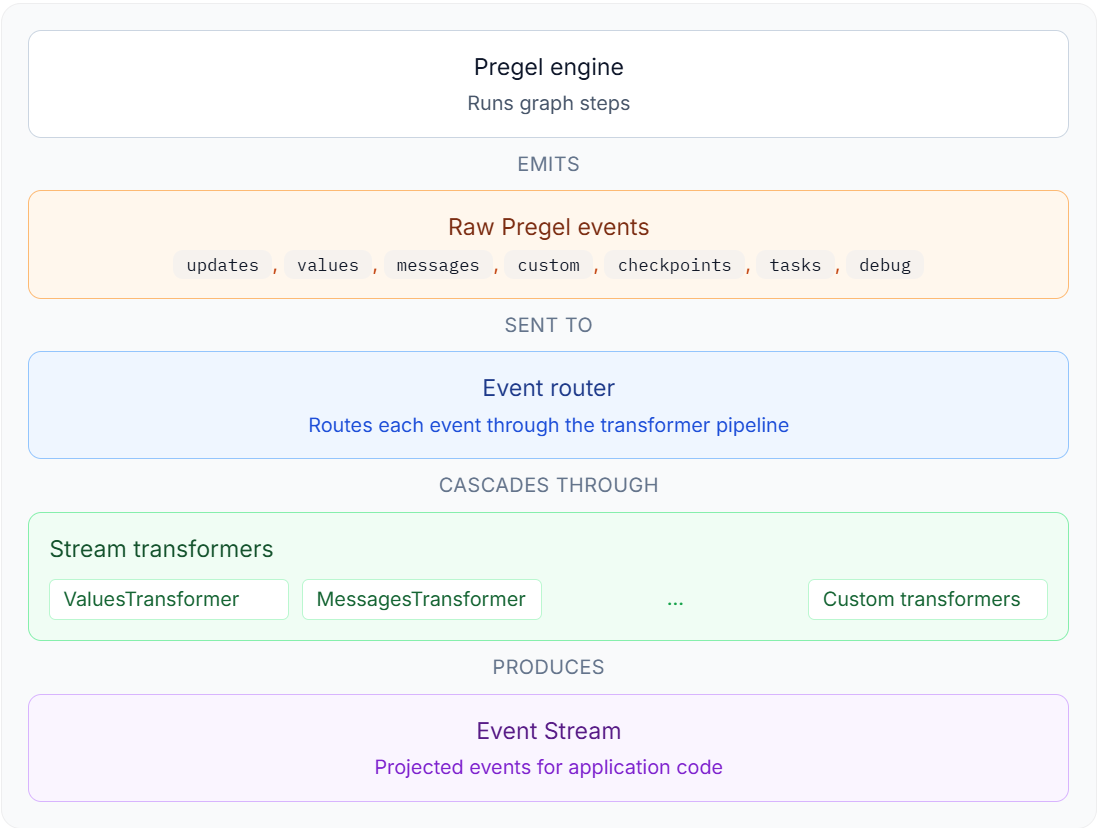

当前版本（**`LangGraph 1.1.2`**）仅支持 `astream_events` 的 **`v1/v2`**，默认版本为 **`v2`**。

> **版本说明**：本节同时收录了课程对 1.2.0 的介绍和 1.1.2 的示例环境说明。1.1.2 示例使用 v1/v2；v3 的协议与类型化投影需在支持它的版本中使用。不要将 `stream(version="v2")` 的 StreamPart 格式与 `astream_events(version="v2")` 的 Runnable 事件协议混为一谈。


## 11.3.2. `astream_events`的用法

事件流不是我们研究的重点，此处仅提供最简示例。

底层也会调用 **`astream`** 来真正触发计算图的运行。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class OverAllState(TypedDict):
    initial_state: str
    node_a_output: str
    node_b_output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "node_a_output": "节点A的输出"
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "node_b_output": "节点B的输出"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
async for chunk in graph.astream_events(
    {"initial_state": "初始状态"},
    version="v2"
):
    print(chunk)
```


**示例输出（精简）**

```text
{
    'event': 'on_chain_start',
    'data': {
        'input': {
            'initial_state': '初始状态'
        }
    },
    'name': 'LangGraph',
    'tags': [],
    'run_id': '<id>',
    'metadata': {},
    'parent_ids': []
...（中间日志/重复事件省略）...
    'run_id': '<id>',
    'name': 'LangGraph',
    'tags': [],
    'metadata': {},
    'parent_ids': []
}
```


**事件分类**：纵向按生命周期分为 `on_xxx_start`（开始）、`on_xxx_stream`（中间结果）、`on_xxx_end`（结束）；横向按 `Runnable` 类型分为以下事件：

| 组件类型 | 事件前缀 | name 示例 |
|:---|:---|:---|
| 模型 | `on_chat_model_*` / `on_llm_*` | `'[model name]'` |
| 工具 | `on_tool_*`（仅 start/end） | `'some_tool'` |
| 检索器 | `on_retriever_*` | `'[retriever name]'` |
| 提示词模板 | `on_prompt_*` | `'[template_name]'` |
| 通用（含编译图、普通节点） | `on_chain_*` | `'format_docs'` 等 |

**关键字段**：

| 字段 | 含义 |
|:---|:---|
| `event` | 事件类型 |
| `run_id` | 当前 Runnable 运行实例的唯一 ID |
| `name` | 运行实例名称 |
| `metadata` | 运行相关元数据 |
| `data` | 事件输入/输出/中间结果 |
| `parent_ids` | 从根运行实例到父运行实例的 ID 链（最外层 LangGraph 为空，子节点包含父 run_id） |


## 12. 子图

状态图节点中调用另外的状态图或直接将另外的状态图作为其节点则后者为子图。

**注意：**

为节点命名时特别注意避开 **`Mermaid`** 关键字，否则拓扑结构渲染可能失败，常见的 **`Mermaid`** 关键字如下


```python
subgraph
end
graph
flowchart
classDef
```


## 12.1. 两种子图嵌入方式

| 方式 | 用法 | 适用场景 | 通信方式 |
|:---|:---|:---|:---|
| **节点函数中调用子图** | 在节点函数内 `subgraph.invoke()` | 父子图状态完全隔离 | 手动做输入输出映射 |
| **子图直接作为父图节点** | `add_node("name", compiled_subgraph)` | 父子图共享状态字段 | 通过共享字段自动通信 |


## 12.1.1. 在节点函数中调用子图

如果父图和子图状态完全隔离，可以用这种方式。

### 12.1.1.1. 用法


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# 构建子图
class SubgraphState(TypedDict):
    raw_text: str # 未清洗文本
    stripped_text: str # 去除收尾空格的文本
    punctuated_text: str # 句尾添加句号的文本

def subgraph_strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "stripped_text": stripped_text
    }

def subgraph_punctuate_node(state: SubgraphState) -> SubgraphState:
    stripped_text = state["stripped_text"]
    punctuated_text = stripped_text + "。"

    return {
        "punctuated_text": punctuated_text
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

subgraph = builder.compile()

# 构建父图
class ParentState(TypedDict):
    input_text: str # 输入的未清洗的文本
    cleaned_text: str # 清洗后的文本

def call_subgraph(state: ParentState) -> ParentState:
    input_text = state["input_text"]

    res = subgraph.invoke({"raw_text": input_text})
    cleaned_text = res["punctuated_text"]
    return {
        "cleaned_text": cleaned_text
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)

builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

parent_graph = builder.compile()

input_text = "   LangGraph 真有意思        "
res = parent_graph.invoke({"input_text": input_text})
cleaned_text = res["cleaned_text"]
print("=" * 30, "->   原始文本   <-", "=" * 30)
print(input_text)
print("=" * 30, "-> 清洗后的文本 <-", "=" * 30)
print(cleaned_text)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


调用 **`get_graph()`** 时传递的 **`xray=True`** 表示自动解析并递归获取子图的拓扑结构。


```text
============================== ->   原始文本   <- ==============================
   LangGraph 真有意思        
============================== -> 清洗后的文本 <- ==============================
LangGraph 真有意思。
```


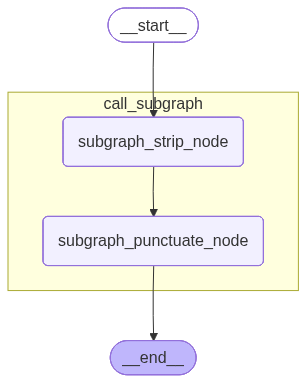

**注意：**

当前方式的子图信息依赖于 **`LangGraph`** 对于节点函数代码的解析，解析的关键代码如下


```python
res = subgraph.invoke({"raw_text": input_text})
```


这是推荐的写法，调用子图时最好不要链式调用，否则解析失败，**`LangGraph`** 可能无法感知子图，这不仅会导致 **`display`** 渲染时不包含子图的拓扑结构，还会导致启用检查点存储器时，无法查看子图检查点快照。

**错误写法示例如下**

当前案例看不到效果，下文的 **`Multi-turn`** 案例能看到差别


```python
assistant_response = subgraph.invoke(
    {"messages": messages}
)["messages"][-1].content
```


此时，**`LangGraph`** 无法感知这里的子图 **`subgraph`**

**正确写法如下**


```python
subgraph_response = subgraph.invoke(
    {"messages": messages}
)

assistant_response = subgraph_response["messages"][-1].content
```


### 12.1.1.2. 查看子图

在上述代码的基础上执行以下代码


```python
list(parent_graph.get_subgraphs())
```


**结果如下**


```text
[('call_subgraph',
  <langgraph.graph.state.CompiledStateGraph at 0x19bd9e84ec0>)]
```


## 12.1.2. 子图直接作为父图的节点

### 12.1.2.1. 用法


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# 定义全局共享状态
class OverAllState(TypedDict):
    raw_text: str # 未清洗文本
    cleaned_text: str # 清洗后的文本

# 构建子图
def subgraph_strip_node(state: OverAllState) -> OverAllState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "cleaned_text": stripped_text
    }

def subgraph_punctuate_node(state: OverAllState) -> OverAllState:
    cleaned_text = state["cleaned_text"]
    punctuated_text = cleaned_text + "。"

    return {
        "cleaned_text": punctuated_text
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

subgraph = builder.compile()

# 构建父图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_node", subgraph)

builder.add_edge(START, "subgraph_node")
builder.add_edge("subgraph_node", END)

parent_graph = builder.compile()

raw_text = "   LangGraph 真有意思        "
res = parent_graph.invoke({"raw_text": raw_text})
cleaned_text = res["cleaned_text"]
print("=" * 30, "->   原始文本   <-", "=" * 30)
print(raw_text)
print("=" * 30, "-> 清洗后的文本 <-", "=" * 30)
print(cleaned_text)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


```text
============================== ->   原始文本   <- ==============================
   LangGraph 真有意思        
============================== -> 清洗后的文本 <- ==============================
LangGraph 真有意思。
```


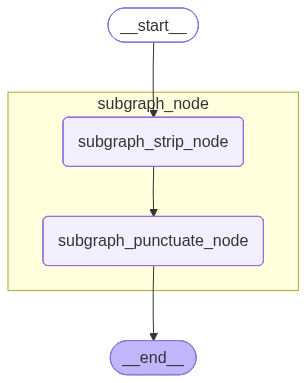

### 12.1.2.2. 查看子图


```python
list(parent_graph.get_subgraphs())
```


```text
[('subgraph_node',
  <langgraph.graph.state.CompiledStateGraph at 0x297c50a2520>)]
```


## 12.2.1. 查看子图检查点快照


本节测试都依赖于以下示例


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

# 构建子图
class SubgraphState(TypedDict):
    raw_text: str # 未清洗文本
    stripped_text: str # 去除收尾空格的文本
    punctuated_text: str # 句尾添加句号的文本

def subgraph_strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "stripped_text": stripped_text
    }

def subgraph_punctuate_node(state: SubgraphState) -> SubgraphState:
    stripped_text = state["stripped_text"]
    punctuated_text = stripped_text + "。"

    return {
        "punctuated_text": punctuated_text
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

subgraph = builder.compile()

# 构建父图
class ParentState(TypedDict):
    input_text: str # 输入的未清洗的文本
    cleaned_text: str # 清洗后的文本

def call_subgraph(state: ParentState) -> ParentState:
    input_text = state["input_text"]

    res = subgraph.invoke({"raw_text": input_text})
    cleaned_text = res["punctuated_text"]
    return {
        "cleaned_text": cleaned_text
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)

builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer=InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

input_text = "   LangGraph 真有意思        "
config={"configurable": {"thread_id": "observe_checkpoint_1"}}
res = parent_graph.invoke(
    {"input_text": input_text},
    config=config
)
cleaned_text = res["cleaned_text"]
print("=" * 30, "->   原始文本   <-", "=" * 30)
print(input_text)
print("=" * 30, "-> 清洗后的文本 <-", "=" * 30)
print(cleaned_text)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


```text
============================== ->   原始文本   <- ==============================
   LangGraph 真有意思        
============================== -> 清洗后的文本 <- ==============================
LangGraph 真有意思。
```


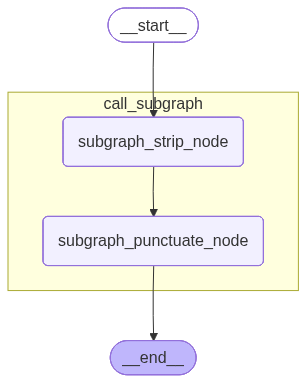


## 12.2.1.1. 在父图检查点快照中查看子图信息

**获取父图历史检查点列表**


```python
histories = list(parent_graph.get_state_history(config=config))
histories
```


**结果如下**


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
        values={
            'input_text': '   LangGraph 真有意思        ',
            'cleaned_text': 'LangGraph 真有意思。'
        },
        next=(),
        config={
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
            'source': 'loop',
            'step': 1,
            'parents': {}
        parent_config={
            'configurable': {
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
...（中间快照省略）...
                interrupts=(),
                state=None,
                result={
                    'input_text': '   LangGraph 真有意思        '
        interrupts=()
    )
```


可以看到，超步为 **`0`** 的快照下的 **`tasks`** 字段下只有一个任务实例，该任务实例在编号为 **`1`** 的超步执行，其中的 **`state`** 字段记录了子图检查点的 **`thread_id`** 和 **`checkpoint_ns`**，如下所示：


```python
state={
    'configurable': {
        'thread_id': 'observe_checkpoint_1',
        'checkpoint_ns': 'call_subgraph:9923d4be-9845-576d-785f-5b1d6da9a94f'
    }
}
```


- **`thread_id`**：整个线程的唯一 **`ID`**，和父图一致

- **`checkpoint_ns`**：子图命名空间，格式为


```text
  <子图所属父图节点名称>:<子图所属父图任务ID>
```


  根图的 checkpoint_ns 通常为空字符串；子图用非空命名空间定位自己的执行历史：

  - 父图的 **`checkpoint_ns`** 仍为空字符串
  - 子图的 **`checkpoint_ns`** 遵循以上格式

  当嵌套层级不止一层时，命名空间将会通过 **`|`** 拼接，具体来说，假设拓扑结构如下：


```text
  父图
  └── call_subgraph          # 调用子图 A
      └── call_inner_graph   # 子图 A 调用子图 B
```


  那么命名空间为


```text
  父图：
  ""
  
  子图 A：
  call_subgraph:<task_id_1>
  
  子图 B：
  call_subgraph:<task_id_1>|call_inner_graph:<task_id_2>
```


  依次类推。


## 12.2.1.2. 在父图检查点快照中展开子图最新快照

我们可以在父图的 **`state`** 字段中展开子图快照，也就是将 **`state`** 字段的值替换为子图的最新检查点快照

### 12.2.1.2.1. 获取父图检查点配置

超步为 **`0`** 的检查点记录了子图的配置，所以我们要获取这个快照的父图配置，观察检查点快照列表可知：快照列表按照超步编号降序排列，且最小超步为 **`-1`**，取列表的倒数第二个元素即可拿到超步编号为 **`0`** 的检查点快照。

**代码如下**


```python
parent_config = histories[-2].config
parent_config
```


**结果如下**


```python
{
  'configurable': {
    'thread_id': 'observe_checkpoint_1',
    'checkpoint_ns': '',
    'checkpoint_id': '1f16fd86-33fb-6847-8000-8914ff1be716'
  }
}
```


### 12.2.1.2.2. 展开子图快照

在调用 **`get_state()`** 时传递带有 **`checkpoint_id`** 的父图配置，并传递 **`subgraphs=True`** 即可展开子图快照。


```python
parent_graph.get_state(config=parent_config, subgraphs=True)
```


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
  values={
    'input_text': '   LangGraph 真有意思        '
  next=(
    'call_subgraph',
  ),
      'thread_id': 'observe_checkpoint_1',
      'checkpoint_ns': '',
      'checkpoint_id': '<id>'
    }
    'source': 'loop',
    'step': 0,
    'parents': {}
  parent_config={
    'configurable': {
      'thread_id': 'observe_checkpoint_1',
      'checkpoint_ns': '',
      'checkpoint_id': '<id>'
    }
...（中间快照省略）...
      ),
      result={
        'cleaned_text': 'LangGraph 真有意思。'
      }
  interrupts=()
)
```


可以看到，**`state`** 字段已展开为子图的最新检查点快照。


## 12.2.1.3. 获取子图配置，查看完整子图检查点列表

某些场景下，我们希望查看完整的子图检查点快照列表，此时只需要将包含 **`thread_id`** 和子图命名空间 **`checkpoint_ns`** 的配置信息传递给 **`get_state_history()`** 即可实现。

### 12.2.1.3.1. 获取子图检查点配置


```python
subgraph_config = histories[-2].tasks[0].state
subgraph_config
```


**结果如下**


```python
{
  'configurable': {
    'thread_id': 'observe_checkpoint_1',
    'checkpoint_ns': 'call_subgraph:9923d4be-9845-576d-785f-5b1d6da9a94f'
  }
}
```


### 12.2.1.3.2. 查看完整子图检查点快照列表


```python
list(parent_graph.get_state_history(config=subgraph_config))
```


**结果如下**


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
        values={
            'raw_text': '   LangGraph 真有意思        ',
        next=(),
        config={
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': 'call_subgraph:<id>',
                'checkpoint_id': '<id>',
                'checkpoint_map': {
                    'call_subgraph:<id>': '<id>'
                }
            'source': 'loop',
            'step': 2,
            'parents': {
        parent_config={
            'configurable': {
                'thread_id': 'observe_checkpoint_1',
                'checkpoint_ns': 'call_subgraph:<id>',
                'checkpoint_id': '<id>',
...（中间快照省略）...
                interrupts=(),
                state=None,
                result={
                    'raw_text': '   LangGraph 真有意思        '
        interrupts=()
    )
```


- 上述快照的命名空间都不是空字符串，且保持一致，全部属于同一个子图

- **`metadata['parents']`** 记录了父检查点的信息，格式为

  **`<父检查点命名空间>:<父检查点ID>`**

- **`config['configurable']['checkpoint_map']`** 记录了父图和当前子图检查点命名空间和 **`ID`** 的映射关系，包含两个条目，格式如下


```text
  <父图检查点命名空间>:<父图检查点ID>,
  <当前子图检查点命名空间>:<当前子图检查点ID>
```


## 12.2.2. 持久化策略

本节讨论的持久化策略以**父图启用检查点存储器**为前提。子图支持三种策略：

| 策略 | 编译参数 | 检查点保存 | 中断恢复 | 自动跨调用记忆 |
|:---|:---|:---|:---|:---|
| **`Per-invocation`**（默认） | `checkpointer=None` 或省略 | ✓ | ✓ | ✗（同 thread_id 再次调用不加载历史） |
| **`Per-thread`** | `checkpointer=True` | ✓ | ✓ | ✓（同 thread_id 调用加载历史） |
| **`Stateless`** | `checkpointer=False` | ✗ | ✗ | ✗ |

> **三种策略的唯一区别在于子图编译时的 `checkpointer` 参数**，其余代码完全相同。下面按场景组织，每个场景展示一份完整代码，策略切换只需修改一行。


## 12.2.2.1. 场景一：中断（interrupt）

子图节点中使用 `interrupt()` 中断执行，等待用户输入后恢复。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

from loguru import logger

# 定义全局共享状态
class OverAllState(TypedDict):
    raw_text: str # 未清洗文本
    cleaned_text: str # 清洗后的文本

# 构建子图
def subgraph_strip_node(state: OverAllState) -> OverAllState:
    logger.info("子图 subgraph_strip_node 节点执行了")
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "cleaned_text": stripped_text
    }

def subgraph_punctuate_node(state: OverAllState) -> OverAllState:
    logger.info("子图 subgraph_punctuate_node 节点执行了")
    cleaned_text = state["cleaned_text"]
    punctuation = interrupt("您希望在句尾添加的标点符号是？[。/，/！/？/；]")
    punctuation1 = interrupt("您希望在句尾添加的标点符号是？[。/，/！/？/；]")
    punctuated_text = cleaned_text + punctuation + punctuation1

    return {
        "cleaned_text": punctuated_text
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
# subgraph = builder.compile()  # Per-invocation（默认）
# subgraph = builder.compile(checkpointer=True)   # Per-thread
subgraph = builder.compile(checkpointer=False)  # Stateless（中断不可用）
# ==================================================

# 构建父图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("subgraph_node", subgraph)

builder.add_edge(START, "subgraph_node")
builder.add_edge("subgraph_node", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

raw_text = "   LangGraph 真有意思        "
config = {"configurable": {"thread_id": "123"}}
# 首次调用
interrupted_res = parent_graph.invoke(
    {"raw_text": raw_text},
    config=config
)
print("=" * 30, "->   中断信息   <-", "=" * 30)
print(interrupted_res)


from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

# 恢复调用
parent_graph.invoke(
    Command(resume="！"),
    config=config
)
res = parent_graph.invoke(
    Command(resume="！"),
    config=config
)

cleaned_text = res["cleaned_text"]
print("=" * 30, "->   原始文本   <-", "=" * 30)
print(raw_text)
print("=" * 30, "-> 清洗后的文本 <-", "=" * 30)
print(cleaned_text)
```


**运行结果（Per-invocation / Per-thread 均可）**


```text
2026-06-25 09:41:40.629 | INFO     | __main__:subgraph_strip_node:15 - 子图 subgraph_strip_node 节点执行了
2026-06-25 09:41:40.630 | INFO     | __main__:subgraph_punctuate_node:24 - 子图 subgraph_punctuate_node 节点执行了
============================== ->   中断信息   <- ==============================
{'raw_text': '   LangGraph 真有意思        ', '__interrupt__': [Interrupt(value='您希望在句尾添加的标点符号是？[。/，/！/？/；]', id='a4c6479870430be1a857af43cc7eff99')]}
2026-06-25 09:41:40.633 | INFO     | __main__:subgraph_punctuate_node:24 - 子图 subgraph_punctuate_node 节点执行了
============================== ->   原始文本   <- ==============================
   LangGraph 真有意思        
============================== -> 清洗后的文本 <- ==============================
LangGraph 真有意思！
```


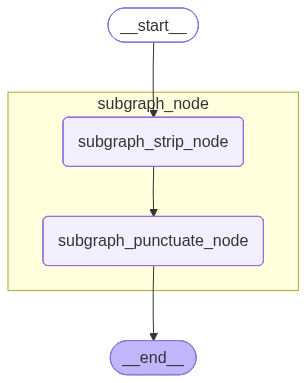

> **策略差异**：父图启用检查点存储器时，`Per-invocation` 与 `Per-thread` 都能保存本次子图执行并恢复中断。`checkpointer=False` 不保存子图内部检查点，不能按相同方式从子图内部断点继续；不要把三种策略视为相同。

| 策略 | 编译参数 | 中断 |
|:---|:---|:---|
| Per-invocation（默认） | `subgraph = builder.compile()` | ✅ |
| Per-thread | `subgraph = builder.compile(checkpointer=True)` | ✅ |
| Stateless | `subgraph = builder.compile(checkpointer=False)` | ❌ |


## 12.2.2.2. 场景二：多轮对话

父图多次调用子图进行 LLM 对话，验证子图是否保留历史消息。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
from langchain_deepseek import ChatDeepSeek

import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 构建子图
def llm_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用子图的 llm_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)

    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
subgraph = builder.compile()  # Per-invocation（默认）：无记忆
# subgraph = builder.compile(checkpointer=True)   # Per-thread：有记忆
# ==================================================

# 构建父图
class OverAllState(TypedDict):
    user_input: str # 用户提问
    assistant_response: str # 助手回答

def call_subgraph(state: OverAllState) -> OverAllState:
    user_input = state["user_input"]

    messages = [
        SystemMessage("尽可能用简短的语言回答"),
        HumanMessage(user_input)
    ]
    subgraph_response = subgraph.invoke(
        {"messages": messages}
    )

    assistant_response = subgraph_response["messages"][-1].content

    return {
        "assistant_response": assistant_response
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "multi-turn-demo"}}

first_invoke = parent_graph.invoke(
    {"user_input": "我是老王，从现在开始，你是小王"},
    config = config
)
print("=" * 30, "-> 第一次调用 <-", "=" * 30)
print(first_invoke)

second_invoke = parent_graph.invoke(
    {"user_input": "我是谁？你是谁？"},
    config = config
)
print("=" * 30, "-> 第二次调用 <-", "=" * 30)
print(second_invoke)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


**Per-invocation 运行结果（无记忆）**


**示例输出（精简）**

```text
[消息 1]
类型：system
内容：尽可能用简短的语言回答

[消息 2]
类型：human
内容：我是老王，从现在开始，你是小王

============================== -> 第一次调用 <- ==============================
...（中间日志/重复事件省略）...
[消息 2]
类型：human
内容：我是谁？你是谁？

============================== -> 第二次调用 <- ==============================
{'user_input': '我是谁？你是谁？', 'assistant_response': '你是用户，我是DeepSeek，一个由深度求索公司开发的AI助手。'}
```


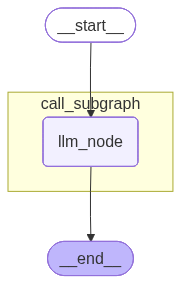

默认模式不会自动加载上一次子图调用的消息。本例每次只传入当前提问，因此第二次调用缺少之前的上下文；父图若显式传入完整消息历史，仍能实现多轮对话。应区分“子图不自动保存跨调用记忆”和“不能对话”。

**Per-thread 运行结果（有记忆）**——仅子图编译改为 `builder.compile(checkpointer=True)`：


**示例输出（精简）**

```text
[消息 1]
类型：system
内容：尽可能用简短的语言回答

[消息 2]
类型：human
内容：我是老王，从现在开始，你是小王

============================== -> 第一次调用 <- ==============================
...（中间日志/重复事件省略）...
[消息 5]
类型：human
内容：我是谁？你是谁？

============================== -> 第二次调用 <- ==============================
{'user_input': '我是谁？你是谁？', 'assistant_response': '老王。小王。'}
```


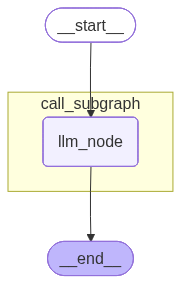

历史消息被保留，上下文连续。**Per-thread 模式适用于子图多轮对话场景。**

> **策略差异**

| 策略 | 编译参数 | 多轮记忆 |
|:---|:---|:---|
| Per-invocation（默认） | `subgraph = builder.compile()` | ❌ 每次调用状态重置 |
| Per-thread | `subgraph = builder.compile(checkpointer=True)` | ✅ 跨调用状态连续 |


## 12.2.2.3. 场景三：多次调用同一子图

父图的一个节点内循环多次调用同一子图。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
from langchain_deepseek import ChatDeepSeek

import sys
from loguru import logger
logger.remove()
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 构建子图
def llm_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用子图的 llm_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
subgraph = builder.compile()  # Per-invocation（默认）：每次调用状态隔离
# subgraph = builder.compile(checkpointer=True)   # Per-thread：历史相互干扰
# ==================================================

# 构建父图
class OverAllState(TypedDict):
    user_inputs: list[str] # 用户提问
    assistant_responses: str # 助手回答

def call_subgraph(state: OverAllState) -> OverAllState:
    user_inputs = state["user_inputs"]

    assistant_responses = []
    for user_input in user_inputs:
        subgraph_response = subgraph.invoke(
            {
                "messages": [
                    SystemMessage("用最简短的话回答用户的提问"),
                    HumanMessage(user_input)
                ]
            }
        )
        assistant_response = subgraph_response["messages"][-1].content
        assistant_responses.append(assistant_response)

    return {
        "assistant_responses": assistant_responses
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "multi-call-same-demo"}}

first_response = parent_graph.invoke(
    {
        "user_inputs": [
            "5*5等于几",
            "10*10等于几"
        ]
    },
    config = config
)
print("=" * 30, "-> 第一次运行结果 <-", "=" * 30)
print(first_response)

second_response = parent_graph.invoke(
    {
        "user_inputs": [
            "再+1呢?",
            "再+10000呢?"
        ]
    },
    config = config
)
print("=" * 30, "-> 第二次运行结果 <-", "=" * 30)
print(second_response)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


**Per-invocation 输出语义（与本例默认编译方式一致）**


**示例输出（精简）**

```text
输出语义示意，模型措辞不固定：
第一次调用：分别收到“5*5等于几”和“10*10等于几”，可回答 25 和 100。
第二次调用：分别只收到“再+1呢?”和“再+10000呢?”，没有前一轮消息。
不能据此保证回答为 26 和 10100；这种连续计算需要传入历史或启用 Per-thread。
```


**课程对照图**：下图展示保留历史后能接续计算的结果，应作为 Per-thread 的对照，而非默认模式的输出。

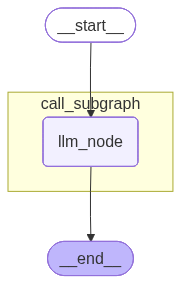

每次调用子图时 `messages` 状态都是独立的。**Per-invocation 适用于父图中多次调用同一子图的场景，调用间互不干扰。**

**Per-thread 行为**（改为 `builder.compile(checkpointer=True)`）：同一节点内的多次子图调用，历史按调用位置独立——即第一次子图调用的历史是连续的，第二次子图调用的历史也是连续的，但两次之间独立。**如果调用顺序发生变化，检查点历史会相互干扰。**

> **策略差异**

| 策略 | 编译参数 | 多次调用同一子图 |
|:---|:---|:---|
| Per-invocation（默认） | `subgraph = builder.compile()` | ✅ 每次调用完全隔离 |
| Per-thread | `subgraph = builder.compile(checkpointer=True)` | ❌ 历史按位置关联，可能干扰 |


## 12.2.2.4. 场景四：多次调用不同子图

父图的一个节点内调用两个不同的子图。


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
from langchain_deepseek import ChatDeepSeek

import sys
from loguru import logger
logger.remove()
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# ==================================================
# 【策略切换点】两个子图的编译参数
# ==================================================

# 构建水果子图
def fruit_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用水果子图的 fruit_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("fruit_node", fruit_node)
builder.add_edge(START, "fruit_node")
builder.add_edge("fruit_node", END)

fruit_subgraph = builder.compile(checkpointer=True)

# 构建蔬菜子图
def vegetable_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用蔬菜子图的 vegetable_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("vegetable_node", vegetable_node)
builder.add_edge(START, "vegetable_node")
builder.add_edge("vegetable_node", END)

vegetable_subgraph = builder.compile(checkpointer=True)

# 构建父图
class OverAllState(TypedDict):
    fruit: str # 水果
    vegetable: str # 蔬菜

    fruit_introduction: str # 水果介绍
    vegetable_introduction: str # 蔬菜介绍

def call_subgraph(state: OverAllState) -> OverAllState:
    fruit = state["fruit"]
    vegetable = state["vegetable"]

    fruit_messages = [
        SystemMessage("用最简短的话介绍用户输入的水果"),
        HumanMessage(fruit)
    ]

    vegetable_messages = [
        SystemMessage("用最简短的话介绍用户输入的蔬菜"),
        HumanMessage(vegetable)
    ]

    fruit_response = fruit_subgraph.invoke({"messages": fruit_messages})
    vegetable_response = vegetable_subgraph.invoke({"messages": vegetable_messages})

    fruit_introduction = fruit_response["messages"][-1].content
    vegetable_introduction = vegetable_response["messages"][-1].content

    return {
        "fruit_introduction": fruit_introduction,
        "vegetable_introduction": vegetable_introduction
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "multi-call-diff-demo"}}

first_response = parent_graph.invoke(
    {
        "fruit": "桑葚",
        "vegetable": "西兰苔"
    },
    config = config
)
print("=" * 30, "-> 第一次运行结果 <-", "=" * 30)
print(first_response)

second_response = parent_graph.invoke(
    {
        "fruit": "香蕉",
        "vegetable": "西兰花"
    },
    config = config
)
print("=" * 30, "-> 第二次运行结果 <-", "=" * 30)
print(second_response)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


**运行结果**


**示例输出（精简）**

```text
[消息 1]
类型：system
内容：用最简短的话介绍用户输入的水果

[消息 2]
类型：human
内容：桑葚


...（中间日志/重复事件省略）...
内容：西兰苔

============================== -> 第一次运行结果 <- ==============================
{'fruit': '桑葚', 'vegetable': '西兰苔', 'fruit_introduction': '紫黑多汁的浆果，味酸甜。', 'vegetable_introduction': '西兰苔是西兰花与芥蓝杂交的蔬菜，以鲜嫩花茎和球花为食。'}
...（第二次调用时水果、蔬菜子图各自保留历史消息，按调用位置独立）
{'fruit': '香蕉', 'vegetable': '西兰花', 'fruit_introduction': '黄色弯月形水果，软糯香甜。', 'vegetable_introduction': '西兰花，绿色花球状蔬菜，营养丰富。'}
```


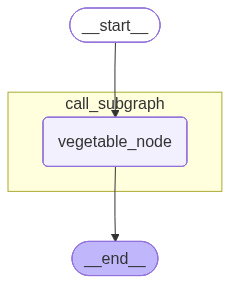

本例在同一个节点中多次调用不同子图，通过专有状态保证了**水果一定发给 `fruit_subgraph`**、**蔬菜一定发给 `vegetable_subgraph`**，一定程度上可以确保不同子图的检查点历史不相互干扰。

但这种靠调用顺序区分的方式不够稳健——如果调用顺序变化，检查点历史也会错乱。官方推荐的做法见下一节。


## 12.2.2.5. 场景五：独立节点调用不同子图（推荐）

为每个子图准备独立的父图节点，这样它们的命名空间是各自的节点名，完全独立。


```python
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
from langchain_deepseek import ChatDeepSeek

import sys
from loguru import logger
logger.remove()
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 构建水果子图
def fruit_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用水果子图的 fruit_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("fruit_node", fruit_node)
builder.add_edge(START, "fruit_node")
builder.add_edge("fruit_node", END)

fruit_subgraph = builder.compile(checkpointer=True)

# 构建蔬菜子图
def vegetable_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    logger.info("=" * 30)
    logger.info("调用蔬菜子图的 vegetable_node 节点，当前的 messages: ")
    for index, message in enumerate(messages, start=1):
        logger.opt(colors=True).info(
            "\n<cyan><bold>[消息 {}]</bold></cyan>\n"
            "<yellow>类型：</yellow><magenta>{}</magenta>\n"
            "<yellow>内容：</yellow><green>{}</green>",
            index,
            message.type,
            message.content
        )
    logger.info("=" * 30)
    response = model.invoke(input=messages)
    ai_msg = AIMessage(content=response.content)

    return {
        "messages": [ai_msg]
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("vegetable_node", vegetable_node)
builder.add_edge(START, "vegetable_node")
builder.add_edge("vegetable_node", END)

vegetable_subgraph = builder.compile(checkpointer=True)

# 构建父图
class OverAllState(TypedDict):
    fruit: str # 水果
    vegetable: str # 蔬菜

    fruit_introduction: str # 水果介绍
    vegetable_introduction: str # 蔬菜介绍

def call_fruit_subgraph(state: OverAllState) -> OverAllState:
    fruit = state["fruit"]

    fruit_messages = [
        SystemMessage("用最简短的话介绍用户输入的水果"),
        HumanMessage(fruit)
    ]

    fruit_response = fruit_subgraph.invoke({"messages": fruit_messages})
    fruit_introduction = fruit_response["messages"][-1].content

    return {
        "fruit_introduction": fruit_introduction
    }

def call_vegetable_subgraph(state: OverAllState) -> OverAllState:
    vegetable = state["vegetable"]

    vegetable_messages = [
        SystemMessage("用最简短的话介绍用户输入的蔬菜"),
        HumanMessage(vegetable)
    ]

    vegetable_response = vegetable_subgraph.invoke({"messages": vegetable_messages})
    vegetable_introduction = vegetable_response["messages"][-1].content

    return {
        "vegetable_introduction": vegetable_introduction
    }

def router(state: OverAllState) -> Sequence[Literal["call_fruit_subgraph", "call_vegetable_subgraph", END]]:
    next_nodes = []
    if state.get("fruit"):
        next_nodes.append("call_fruit_subgraph")
    if state.get("vegetable"):
        next_nodes.append("call_vegetable_subgraph")
    if not next_nodes:
        next_nodes.append(END)
    return next_nodes

builder = StateGraph(state_schema=OverAllState)
builder.add_node("call_fruit_subgraph", call_fruit_subgraph)
builder.add_node("call_vegetable_subgraph", call_vegetable_subgraph)

builder.add_conditional_edges(START, router, path_map=["call_fruit_subgraph", "call_vegetable_subgraph", END])
builder.add_edge("call_fruit_subgraph", END)
builder.add_edge("call_vegetable_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "independent-nodes-demo"}}

first_response = parent_graph.invoke(
    {
        "fruit": "桑葚",
        "vegetable": "西兰苔"
    },
    config = config
)
print("=" * 30, "-> 第一次运行结果 <-", "=" * 30)
print(first_response)

second_response = parent_graph.invoke(
    {
        "fruit": "香蕉",
        "vegetable": "西兰花"
    },
    config = config
)
print("=" * 30, "-> 第二次运行结果 <-", "=" * 30)
print(second_response)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


**运行结果**


**示例输出（精简）**

```text
[消息 1]
类型：system
内容：用最简短的话介绍用户输入的水果


[消息 2]
类型：human
内容：桑葚

...（中间日志/重复事件省略）...
内容：西兰苔

============================== -> 第一次运行结果 <- ==============================
{'fruit': '桑葚', 'vegetable': '西兰苔', 'fruit_introduction': '桑葚是桑树的果实，味甜可食，常被用于制酱或入药。', 'vegetable_introduction': '西兰苔是西兰花和芥蓝的杂交品种。'}
...（第二次调用时，水果子图和蔬菜子图各自保留独立的历史）
{'fruit': '香蕉', 'vegetable': '西兰花', 'fruit_introduction': '香蕉是软甜水果，富含钾，能缓解便秘。', 'vegetable_introduction': '一种绿色花状蔬菜，营养丰富。'}
```


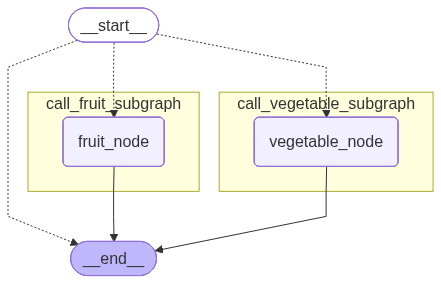

每个子图有独立的父图节点，命名空间为各自的节点名，完全隔离。**这是 Per-thread 模式下多次调用不同子图的推荐做法。**


## 12.2.2.6. 场景六：Stateless 模式

`Stateless` 表示子图不保存内部检查点、不自动保留跨调用历史；单次调用仍有 State，节点仍可读取和更新它。它适合纯计算或由父图显式管理上下文的场景，不能提供子图内部检查点的中断恢复。


```python
from typing import TypedDict, Annotated
from operator import add
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

# 构建子图
class SubgraphState(TypedDict):
    raw_text: str
    clean_texts: Annotated[list[str], add]

def strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    clean_text = raw_text.strip()

    return {
        "clean_texts": [clean_text]
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("strip_node", strip_node)
builder.add_edge(START, "strip_node")
builder.add_edge("strip_node", END)

# ==================================================
# 【策略切换点】只需修改这一行
subgraph = builder.compile(checkpointer=False)  # Stateless：无检查点
# subgraph = builder.compile(checkpointer=True)   # Per-thread：有状态（对比用）
# ==================================================

# 构建父图
class ParentState(TypedDict):
    input_texts: list[str]
    output_texts: Annotated[list[str], add]

def call_subgraph(state: ParentState) -> ParentState:
    input_texts = state["input_texts"]

    output_texts = []
    for input_text in input_texts:
        res = subgraph.invoke({"raw_text": input_text})
        output_texts += res["clean_texts"]

    return {
        "output_texts": output_texts
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "stateless-demo"}}

first_response = parent_graph.invoke(
    {
        "input_texts": ["  LangGraph 真有意思 ", "  我喜欢 LangChain "]
    },
    config = config
)
print("=" * 30, "-> 第一次运行结果 <-", "=" * 30)
print(first_response)

second_response = parent_graph.invoke(
    {
        "input_texts": ["  Hello, LangGraph  ", "  Hello, LangChain "]
    },
    config = config
)
print("=" * 30, "-> 第二次运行结果 <-", "=" * 30)
print(second_response)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


**Stateless 运行结果**


```text
============================== -> 第一次运行结果 <- ==============================
{'input_texts': ['  LangGraph 真有意思 ', '  我喜欢 LangChain '], 'output_texts': ['LangGraph 真有意思', '我喜欢 LangChain']}
============================== -> 第二次运行结果 <- ==============================
{'input_texts': ['  Hello, LangGraph  ', '  Hello, LangChain '], 'output_texts': ['LangGraph 真有意思', '我喜欢 LangChain', 'Hello, LangGraph', 'Hello, LangChain']}
```


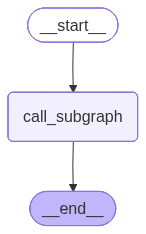

课程截图中没有展开子图内部拓扑。图能否展开还取决于子图的发现方式、嵌入方式及 `get_graph(xray=True)`，不能用截图是否展开判断子图是否有运行时状态或检查点。

**Per-thread 对比结果**（仅改为 `builder.compile(checkpointer=True)`）：


```text
============================== -> 第一次运行结果 <- ==============================
{'input_texts': ['  LangGraph 真有意思 ', '  我喜欢 LangChain '], 'output_texts': ['LangGraph 真有意思', '我喜欢 LangChain']}
============================== -> 第二次运行结果 <- ==============================
{'input_texts': ['  Hello, LangGraph  ', '  Hello, LangChain '], 'output_texts': ['LangGraph 真有意思', '我喜欢 LangChain', 'LangGraph 真有意思', 'Hello, LangGraph', '我喜欢 LangChain', 'Hello, LangChain']}
```


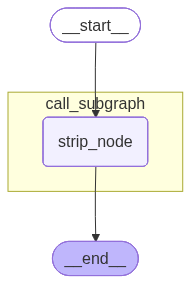

Per-thread 的子图会累计 `clean_texts`。父图再次把包含旧条目的整份子图结果追加到 `output_texts`，因此出现重复。Stateless 的子图每次只处理本次输入，但父图仍启用了检查点和追加 Reducer，所以父图输出仍会保留历史。


## 12.2.2.7. `Per-invocation`和`Per-thread`的设计哲学

默认子图检查点命名空间为 `<节点名称>:<任务ID>`。两种模式的核心差异在于对 `<任务ID>` 的处理：

| 维度 | **`Per-invocation`** | **`Per-thread`** |
|:---|:---|:---|
| 命名空间 | `<节点名称>:<任务ID>` | `<节点名称>`（去掉 `:<任务ID>`） |
| 设计意图 | `<任务ID>` 每次不同 → 每次调用状态独立 | `<节点名称>` 不变 → 跨多次调用状态连续 |
| 同节点多次调用 | `:<任务ID>\|1`, `:<任务ID>\|2` … | `\|1`, `\|2` … |
| 注意事项 | — | 调用顺序变化会导致检查点历史相互干扰；课程所用版本观察到 `get_state_history()` 的问题（属于版本行为，不应当作永久 API 约定），父图检查点仍记录 `:<任务ID>` 格式，需额外处理 |


## 12.2.2.8. 总结

以下以父图启用检查点为前提；“自动记忆”指子图自行加载历史，不包括父图显式传入完整上下文。

| 特性 | Per-invocation（默认） | Per-thread | Stateless |
| --- | --- | --- | --- |
| `checkpointer` 参数 | `None` / 省略 | `True` | `False` |
| 单次调用内的状态 | 有 | 有 | 有 |
| 子图内部中断恢复 | 支持 | 支持 | 不支持 |
| 自动跨调用记忆 | 不保留 | 同线程、同调用位置保留 | 不保留 |
| 多次独立调用 | 每次调用隔离 | 需隔离节点或稳定调用位置 | 每次调用隔离 |
| 查看子图检查点 | 可查看本次执行 | 可查看持续历史 | 不保存内部检查点 |

需要连续对话时，可选择 Per-thread，或由父图维护消息再显式传给子图。选择策略的关键是历史应由谁保存、不同任务的历史如何隔离。


## 12.3. 子图流式运行

只需要在父图调用 **`stream`** 时传递 **`subgraphs=True`** 即可，这样父图和子图的流数据都会汇入同一个流队列，再通过命名空间区分来源。

**需要注意的是**：**`subgraphs=True`** 是在原有父图流数据的基础上，**额外加入子图内部产生的流数据**，并不会用子图数据替代父图数据。它会同时流式返回父图和所有子图的输出。


## 12.3.1. 分析`chunk`格式

**`chunk`** 格式为


```python
(namespace, stream_mode, data)
```


此处的命名空间不同于检查点命名空间，是流处理内部专门用于区分父图和子图流数据的字段。

我们通过模式为 **`updates`** 的简单案例查看数据格式


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# 构建子图
class SubgraphState(TypedDict):
    raw_text: str # 未清洗文本
    stripped_text: str # 去除收尾空格的文本
    punctuated_text: str # 句尾添加句号的文本

def subgraph_strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "stripped_text": stripped_text
    }

def subgraph_punctuate_node(state: SubgraphState) -> SubgraphState:
    stripped_text = state["stripped_text"]
    punctuated_text = stripped_text + "。"

    return {
        "punctuated_text": punctuated_text
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

subgraph = builder.compile()

# 构建父图
class ParentState(TypedDict):
    input_text: str # 输入的未清洗的文本
    cleaned_text: str # 清洗后的文本

def call_subgraph(state: ParentState) -> ParentState:
    input_text = state["input_text"]

    res = subgraph.invoke({"raw_text": input_text})
    cleaned_text = res["punctuated_text"]
    return {
        "cleaned_text": cleaned_text
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)

builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

parent_graph = builder.compile()

input_text = "   LangGraph 真有意思        "
for chunk in parent_graph.stream(
    {"input_text": input_text},
    subgraphs=True,
    stream_mode=["updates"]
):
    print(chunk)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


```python
(
    (
        'call_subgraph:4daa7290-d5c9-ae96-849e-d2f1dafadd17',
    ),
    'updates',
    {
        'subgraph_strip_node': {
            'stripped_text': 'LangGraph 真有意思'
        }
    }
)
(
    (
        'call_subgraph:4daa7290-d5c9-ae96-849e-d2f1dafadd17',
    ),
    'updates',
    {
        'subgraph_punctuate_node': {
            'punctuated_text': 'LangGraph 真有意思。'
        }
    }
)
(
    (),
    'updates',
    {
        'call_subgraph': {
            'cleaned_text': 'LangGraph 真有意思。'
        }
    }
)
```


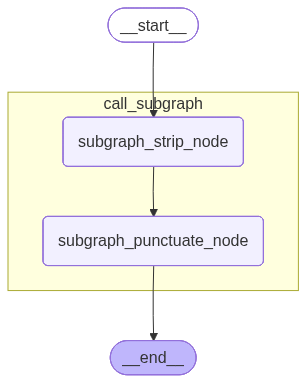

**流数据命名空间规则**：

| 来源 | 命名空间 | 备注 |
|:---|:---|:---|
| 父图 | `()`（空元组） | |
| 子图（常规） | `(<父图节点名>:<父图任务ID>,)` | |
| 子图（Per-thread） | `(<父图节点名>,)` | 与检查点命名空间一致 |


## 12.3.2. 多轮对话消息流处理


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import HumanMessage, SystemMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 构建子图
class SubgraphState(MessagesState):
    system_prompt: SystemMessage

def llm_mode(state: SubgraphState) -> SubgraphState:
    system_prompt = state["system_prompt"]
    messages = state["messages"]

    response = model.invoke([system_prompt] + messages)
    return {
        "messages": [response]
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("llm_mode", llm_mode)
builder.add_edge(START, "llm_mode")
builder.add_edge("llm_mode", END)

subgraph = builder.compile(checkpointer=True)

# 构建父图
class ParentState(TypedDict):
    user_input: str
    assistant_response: str

def call_subgraph(state: ParentState) -> ParentState:
    user_input = state["user_input"]

    response = subgraph.invoke(
        {
            "system_prompt": SystemMessage("你是个善解人意的助手"),
            "messages": [HumanMessage(user_input)]
        }
    )

    assistant_response = response["messages"][-1].content

    return {
        "assistant_response": assistant_response
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "subgraph_stream_test"}}

print("\n", "=" * 30, "-> 第一次运行结果 <-", "=" * 30)
# chunk 形如
# (('call_subgraph',), 'messages', (AIMessageChunk(content='', additional_kwargs={}, response_metadata={'model_provider': 'deepseek'}, id='lc_run--019efd65-c54e-7012-912e-29ff4f84328e', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'thread_id': 'subgraph_stream_test', 'langgraph_step': 1, 'langgraph_node': 'llm_mode', 'langgraph_triggers': ('branch:to:llm_mode',), 'langgraph_path': ('__pregel_pull', 'llm_mode'), 'langgraph_checkpoint_ns': 'call_subgraph|llm_mode:55577c3e-22da-877a-c77b-f16bdbcd2c6c', 'checkpoint_ns': 'call_subgraph:9c469391-f094-1c1b-c5d7-6578f1603151', 'ls_provider': 'deepseek', 'ls_model_name': 'deepseek-v4-flash', 'ls_model_type': 'chat', 'ls_temperature': None}))
for chunk in parent_graph.stream(
    {
        "user_input": "花儿为什么这样红？"
    },
    config=config,
    subgraphs=True,
    stream_mode=["messages"]
):
    print(chunk[2][0].content, end="", flush=True)

print("\n", "=" * 30, "-> 第二次运行结果 <-", "=" * 30)
for chunk in parent_graph.stream(
    {
        "user_input": "刚才我们聊了什么？"
    },
    config=config,
    subgraphs=True,
    stream_mode=["messages"]
):
    print(chunk[2][0].content, end="", flush=True)

from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)
```


```text
 ============================== -> 第一次运行结果 <- ==============================
“花儿为什么这样红”是一个经典的问题，可以从不同角度来理解：

1. **自然科学的视角**：花朵的颜色主要由花瓣中的色素决定，尤其是**花青素**（anthocyanins）。花青素在酸性环境下呈现红色，在碱性环境下偏向蓝色。某些花朵（如玫瑰、山茶花）细胞液偏酸性，因此吸收阳光中的蓝绿光，反射红光，让我们看到鲜艳的红色。此外，红色也能吸引蜂鸟等传粉动物，帮助植物繁殖。

2. **文化艺术的视角**：这是一首传唱已久的中国民歌（《花儿为什么这样红》），由雷振邦作曲，是电影《冰山上的来客》的插曲。歌词用“花儿”比喻纯洁、热烈的情感，红色象征着爱情、勇气或革命的赤诚。

3. **诗意隐喻**：就像“花儿为什么这样红”可以指代生命的热情、青春的绽放，或者经风雨后更加绚烂的坚韧。红色的花朵也常被赋予“美好而短暂”的哲学意味。

如果你指的是特定语境（比如学生物的朋友、教孩子、写赏析），我可以把回答调整得更具体。🌹
 ============================== -> 第二次运行结果 <- ==============================
我们刚才聊了“花儿为什么这样红”这个话题。我分别从自然科学（花青素与酸碱性）、文化艺术（经典民歌《花儿为什么这样红》）以及诗意隐喻三个角度做了解答。如果你有更多想深入的方向，随时告诉我～
```


实际测试可以看到模型返回的消息是 **逐`token`** 返回的。

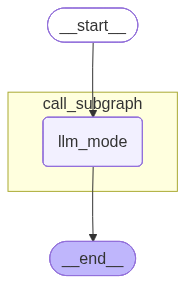


## 12.4. 子图动态路由

在子图中可以通过 **`Command`** 动态路由到父图节点，只要将参数 **`graph`** 的值设置为 **`Command.PARENT`** 即可，如下所示


```python
return Command(
    update={
        "fruits": fruits,
        "vegetables": vegetables
    },
    goto="router_node",
    graph=Command.PARENT
)
```


```python
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
from loguru import logger

# ==================== 子图 ====================
class SubState(TypedDict):
    data: str

def sub_node(state: SubState) -> Command:
    """子图节点：执行后动态路由回父图的 parent_router"""
    logger.info("[子图] sub_node 执行")
    return Command(
        update={"data": state["data"] + " → 子图"},
        goto="node_b",       # 路由到父图节点
        graph=Command.PARENT,       # 指定目标为父图
    )

sub_builder = StateGraph(state_schema=SubState)
sub_builder.add_node("sub_node", sub_node)
sub_builder.add_edge(START, "sub_node")
sub_graph = sub_builder.compile()

# ==================== 父图 ====================
class ParentState(TypedDict):
    data: str

def node_a(state: ParentState) -> ParentState:
    print("[父图] node_a 执行")
    return {"visited_a": True}

def node_b(state: ParentState) -> ParentState:
    print("[父图] node_b 执行")
    return {"visited_b": True}

parent_builder = StateGraph(state_schema=ParentState)
parent_builder.add_node(
    "sub_graph", sub_graph
)

parent_builder.add_node("node_a", node_a)
parent_builder.add_node("node_b", node_b)
parent_builder.add_edge(START, "sub_graph")
parent_builder.add_edge("node_a", "node_b")
parent_builder.add_edge("node_b", END)

parent_graph = parent_builder.compile()

result = parent_graph.invoke({"data": "初始"})
print(f"\n最终结果: {result}")

from IPython.display import display
display(parent_graph)
```


**要点**：

1. 本例通过 `Command(goto="node_b", graph=Command.PARENT)` 路由到父图的 `node_b`；`graph` 决定跳转作用域。若同时更新父图字段，应遵守父图的 Schema 和 Reducer 规则。

2. 返回值注解会参与图构建及可视化。本课程示例使用未参数化的 `Command`；课程记录的下列异常来自图编译时的目标节点校验，并不是 Python 静态类型系统“不认识父图节点”。如果版本把返回注解的目标当成本图节点检查，应按该版本的父图路由示例处理，不能概括为 `Command[Literal[...]]` 永远不可用。


```text
   ValueError: Found edge ending at unknown node `parent_router`
```


3. 添加子图节点时通过 **`destinations`** 声明下游节点，便于渲染图结构时正确描绘拓扑关系


```text
   builder.add_node(
       "sub_graph", sub_graph,
       destinations=("parent_router",)
   )
```


   不加 **`destinations`** 不会影响动态路由，只是渲染的图结构不能正确描绘拓扑。

> 该课程片段中的 `visited_a`、`visited_b` 未声明在 `ParentState` 中。如需在最终状态中保存访问标记，应先把字段加入 Schema；不要依赖未声明字段作为输出。


## 13.1. 概述


**`LangGraph`** 官方总结了常用的状态图设计模式，如下

| 模式                      | 图结构                    | 运行时动态性 | 核心 `LangGraph` 能力                         |
| ------------------------- | ------------------------- | ------------ | --------------------------------------------- |
| **`Prompt Chaining`**     | 顺序链                    | 低           | 静态边、条件边                                |
| **`Parallelization`**     | 固定 **`Fan-out/Fan-in`** | 低           | 并行超步、汇聚                                |
| **`Routing`**             | 条件分支                  | 中           | 结构化输出、条件边                            |
| **`Orchestrator-worker`** | 动态 **`Fan-out/Fan-in`** | 高           | **`Send`**、**`WorkerState`**、**`Reducer`**  |
| **`Evaluator-optimizer`** | 反馈循环                  | 中           | 条件边、循环、反馈状态                        |
| **`Agent`**               | 自主决策循环              | 最高         | **`MessagesState`**、工具调用、**`ToolNode`** |


## 13.2.1. `Prompt Chaining`：提示词链


### 13.2.1.1. 核心思想

将一个复杂任务拆分成若干个顺序执行的小任务：


```text
输入
 ↓
任务 A
 ↓
任务 B
 ↓
任务 C
 ↓
输出
```


后一个节点依赖前一个节点的结果。

适合：

* 翻译 → 校对 → 润色
* 生成内容 → 检查一致性 → 修订
* 提取信息 → 分类 → 格式化
* 需求分析 → 生成代码 → 代码解释

官方示例是：


```text
生成笑话
   ↓
检查是否合格
  ├─ 合格 → END
  └─ 不合格 → 改进笑话 → 最终润色 → END
```


所以 **`Prompt Chaining`** 不一定只是简单的直线，也可以在中间加入一个 **`Gate`，质量门控节点**。

**`Prompt Chaining`** 的核心是：

> **将复杂任务拆解为可独立验证的阶段，并把每一阶段的结果记录下来向后传递。**

它的优点是执行过程稳定且易于调试；缺点是流程固定，无法处理未知数量或高度动态的任务。

### 13.2.1.2. 示例


```python
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END

from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 图状态
class OverAllState(TypedDict):
    topic: str
    joke: str
    improved_joke: str
    final_joke: str

# 节点
def generate_joke(state: OverAllState) -> OverAllState:
    """第一次调用大模型，生成初始笑话"""

    msg = model.invoke(
        [HumanMessage(content=f"写一个关于“{state['topic']}”的简短笑话")]
    )
    return {"joke": msg.content}

def check_punchline(state: OverAllState) -> Literal["pass", "no_pass"]:
    """判断笑话中是否包含包袱"""

    # 简单判断：笑话中是否包含问号或感叹号
    if "?" in state["joke"] or "!" in state["joke"]:
        return "pass"
    return "no_pass"

def improve_joke(state: OverAllState) -> OverAllState:
    """第二次调用大模型，通过添加双关语改进笑话"""

    msg = model.invoke(
        [HumanMessage(content=f"通过添加双关语，让下面这个笑话变得更有趣：\n{state['joke']}")]
    )
    return {"improved_joke": msg.content}

def polish_joke(state: OverAllState) -> OverAllState:
    """第三次调用大模型，对笑话进行最终润色"""

    msg = model.invoke(
        [HumanMessage(content=f"为下面这个笑话添加一个出人意料的反转：\n{state['improved_joke']}")]
    )
    return {"final_joke": msg.content}

# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("generate_joke", generate_joke)
builder.add_node("improve_joke", improve_joke)
builder.add_node("polish_joke", polish_joke)

# 添加边，连接各个节点
builder.add_edge(START, "generate_joke")
builder.add_conditional_edges(
    "generate_joke",
    check_punchline,
    {
        "no_pass": "improve_joke",
        "pass": END,
    },
)
builder.add_edge("improve_joke", "polish_joke")
builder.add_edge("polish_joke", END)

# 编译工作流
graph = builder.compile()

# 调用工作流
response = graph.invoke({"topic": "猫"})
print(response)

# 绘制拓扑结构
from IPython.display import display
display(graph)
```


```python
{
    'topic': '猫',
    'joke': '一只猫去面试，面试官问：“你有什么特长？”  \n猫淡定地回答：“我能用尾巴画圆。”  \n面试官惊讶：“真的吗？演示一下。”  \n猫转身，尾巴甩了几下，画出一个完美的圆。  \n面试官鼓掌：“太好了！你被录取了！”  \n第二天，猫上班了，发现它被送到了数学实验室——负责画π。',
    'improved_joke': '加了一点数学梗和双关后，版本如下：\n\n---\n\n一只猫去面试，面试官问：“你有什么特长？”  \n猫淡定地回答：“我能用尾巴画圆。”  \n面试官惊讶：“真的吗？演示一下。”  \n猫转身，尾巴甩了几下，画出一个完美的圆。  \n面试官鼓掌：“太好了！你被录取了！”  \n\n第二天，猫上班了，发现它被送到了数学实验室——**负责画π**。  \n\n猫叹了口气，说：“**原来我的‘圆’满人生，终究逃不过π的‘鼠’命。”**  \n\n（双关解析：  \n1. “π”音同“派”，既指圆周率，也暗示“被派遣”去画圆。  \n2. “鼠命”谐音“宿命”，同时猫抓老鼠，这里暗指猫被困在数学“鼠”洞（无限不循环小数）里，永远画不完。）',
    'final_joke': '---\n\n**反转版：**  \n第二天，猫上班了，发现它被送到了数学实验室——**负责画π**。  \n\n猫叹了口气，说：“原来我的‘圆’满人生，终究逃不过π的‘鼠’命。”  \n\n话音刚落，实验室主任推门进来，是个戴眼镜的仓鼠。仓鼠拍了拍猫的尾巴，微笑道：“别担心，我们用的是**有理数**——你每天只用画前100位，剩下的**无限循环**，由我们**鼠**类负责演算。”  \n\n猫愣了一下，突然跳起来：“等等！你是说——我画圆，你们算剩下的尾巴？”  \n\n仓鼠点头：“对，这叫……**π的‘分工’合作**。”  \n\n猫沉默三秒，忽然掏出手机：“那我得先给抓老鼠的同行打个电话——告诉他们，**‘有理’走遍天下，无理寸步难行**。”  \n\n（双关补充：  \n1. **“有理数”** 双关：既指数学上有理数（可终止或循环），也暗示“有道理的反转”——猫的“无限宿命”被仓鼠强行打断。  \n2. **“剩下的尾巴”** 双关：猫的尾巴画圆，但仓鼠们负责“补完”无限小数，字面与数学双关。  \n3. **“有理走遍天下”** 化用俗语，暗讽“有理数”才是猫的出路，而“无理”的π已变成职场协作梗。）'
}
```


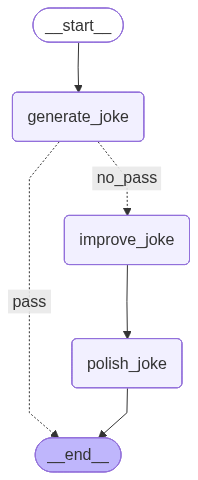

---


## 13.2.2. `Parallelization`：并行化

### 13.2.2.1. 核心思想

把相互独立的任务同时执行，最后汇总结果：


```text
                 ┌→ 任务 A ─┐
输入 → Fan-out ──┼→ 任务 B ─┼→ 聚合 → 输出
                 └→ 任务 C ─┘
```


官方将并行化分成两种用途：

1. **任务拆分**
   * 一个节点检查关键词
   * 一个节点检查格式
   * 一个节点检查事实准确性
   
2. **多次独立判断**
   * 多个模型或多个提示词分别评分
   * 最后投票、平均或综合判断

前者主要提升速度，后者主要提升置信度。

### 13.2.2.2. 示例


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 图状态
class OverAllState(TypedDict):
    topic: str
    joke: str
    story: str
    poem: str
    combined_output: str

# 节点
def call_model_1(state: OverAllState) -> OverAllState:
    """第一次调用大模型，生成笑话"""

    msg = model.invoke(
        [HumanMessage(content=f"写一个关于“{state['topic']}”的简短的笑话")]
    )
    return {"joke": msg.content}

def call_model_2(state: OverAllState) -> OverAllState:
    """第二次调用大模型，生成故事"""

    msg = model.invoke(
        [HumanMessage(content=f"写一个关于“{state['topic']}”的简短的故事")]
    )
    return {"story": msg.content}

def call_model_3(state: OverAllState) -> OverAllState:
    """第三次调用大模型，生成诗歌"""

    msg = model.invoke(
        [HumanMessage(content=f"写一首关于“{state['topic']}”的简短的诗")]
    )
    return {"poem": msg.content}

def aggregator(state: OverAllState) -> OverAllState:
    """将笑话、故事和诗歌合并为单一输出"""

    combined = f"下面是一个关于“{state['topic']}”的故事、笑话和诗歌！\n\n"
    combined += f"故事：\n{state['story']}\n\n"
    combined += f"笑话：\n{state['joke']}\n\n"
    combined += f"诗歌：\n{state['poem']}"
    return {"combined_output": combined}

# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("call_model_1", call_model_1)
builder.add_node("call_model_2", call_model_2)
builder.add_node("call_model_3", call_model_3)
builder.add_node("aggregator", aggregator)

# 添加边，连接各个节点
builder.add_edge(START, "call_model_1")
builder.add_edge(START, "call_model_2")
builder.add_edge(START, "call_model_3")
builder.add_edge(["call_model_1", "call_model_2", "call_model_3"], "aggregator")
builder.add_edge("aggregator", END)

graph = builder.compile()

# 调用工作流
response = graph.invoke({"topic": "猫"})
print(response)

from IPython.display import display
display(graph)
```


```python
{
    'topic': '猫',
    'joke': '“为什么猫总是赢不了电脑游戏？”\n“因为鼠标（鼠）一出现，它就光顾着抓屏（屏幕）了……”',
    'story': '# 猫的故事\n\n老张退休那年，在楼下捡到一只瘦骨嶙峋的橘猫。\n\n他本不爱猫，但看它可怜，便每天在楼道口放一碗剩饭。猫很警惕，非要等他走远了才肯吃。就这样喂了三个月，猫终于允许他靠近一臂的距离。\n\n半年后的一天夜里，老张突发心梗，倒在客厅地板上，手机摔在茶几底下，怎么也够不着。意识模糊间，他感到一团温热的东西贴上了他的胸口——是那只橘猫。它不知怎么钻进了他家门。\n\n猫用头蹭他的手，蹭他的脸，见他没反应，便冲进屋里的每一个房间，歇斯底里地叫。最后它跳上窗台，用爪子疯狂拍打玻璃，叫声惊动了楼下乘凉的邻居。\n\n120赶到时，老张已经在地上躺了将近一个小时。医生说，再晚十分钟，就悬了。\n\n出院后，橘猫正式住进了老张家。老张给它取名“富贵”，逢人就说：“我家富贵啊，有九条命，分了我一条。”\n\n富贵永远听不懂这些话。它只是每天黄昏，准时跳上老张的膝盖，把一团温暖塞进他的怀里，呼噜呼噜地睡去。',
    'poem': '## 《猫》\n\n黄昏被毛茸茸地踩碎，\n肚皮起伏如钟摆，\n眼睫间，星辰坠落。\n当琥珀瞳孔转动，\n整片夜色都来蜷卧。',
    'combined_output': '下面是一个关于“猫”的故事、笑话和诗歌！\n\n故事：\n# 猫的故事\n\n老张退休那年，在楼下捡到一只瘦骨嶙峋的橘猫。\n\n他本不爱猫，但看它可怜，便每天在楼道口放一碗剩饭。猫很警惕，非要等他走远了才肯吃。就这样喂了三个月，猫终于允许他靠近一臂的距离。\n\n半年后的一天夜里，老张突发心梗，倒在客厅地板上，手机摔在茶几底下，怎么也够不着。意识模糊间，他感到一团温热的东西贴上了他的胸口——是那只橘猫。它不知怎么钻进了他家门。\n\n猫用头蹭他的手，蹭他的脸，见他没反应，便冲进屋里的每一个房间，歇斯底里地叫。最后它跳上窗台，用爪子疯狂拍打玻璃，叫声惊动了楼下乘凉的邻居。\n\n120赶到时，老张已经在地上躺了将近一个小时。医生说，再晚十分钟，就悬了。\n\n出院后，橘猫正式住进了老张家。老张给它取名“富贵”，逢人就说：“我家富贵啊，有九条命，分了我一条。”\n\n富贵永远听不懂这些话。它只是每天黄昏，准时跳上老张的膝盖，把一团温暖塞进他的怀里，呼噜呼噜地睡去。\n\n笑话：\n“为什么猫总是赢不了电脑游戏？”\n“因为鼠标（鼠）一出现，它就光顾着抓屏（屏幕）了……”\n\n诗歌：\n## 《猫》\n\n黄昏被毛茸茸地踩碎，\n肚皮起伏如钟摆，\n眼睫间，星辰坠落。\n当琥珀瞳孔转动，\n整片夜色都来蜷卧。'
}
```


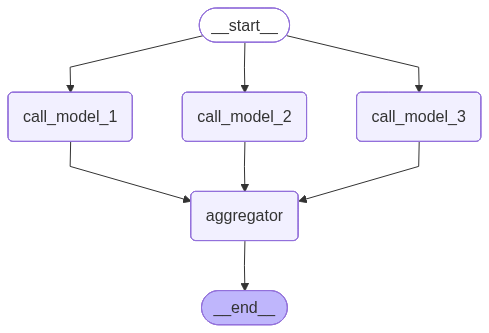

---


## 13.2.3. `Routing`：路由

### 13.2.3.1. 核心思想

先识别输入类型，再把请求送到专门的处理流程：


```text
                    ┌→ 退款流程
输入 → 路由判断节点 ─┼→ 售价咨询流程
                    └→ 商品推荐流程
```


它适合不同类型请求需要不同处理逻辑的场景，例如：

* 售前、售后、退款分类
* 普通问答、代码生成、数据分析
* 文本、图片、音频请求分类
* 不同领域知识库的选择

### 13.2.3.2. 设计原则

最佳实践：

* **`LLM` 节点**负责语义判断；
* **路由函数**负责把结构化结果映射到节点；
* **业务节点**负责真正处理任务。

不要让路由 LLM 直接返回任意节点名，否则模型输出和图结构会过度耦合，也难以进行类型检查和异常兜底。

### 13.2.3.3. 示例


```python
from pydantic import BaseModel, Field
from typing import Literal,TypedDict
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage, SystemMessage

from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 定义用于结构化输出的 Schema，作为路由判断依据
class Route(BaseModel):
    step: Literal["poem", "story", "joke"] = Field(
        None,
        description="路由流程中的下一执行步骤",
    )

# 为大模型添加结构化输出能力
router = model.with_structured_output(Route)

# 图状态
class OverAllState(TypedDict):
    input: str
    decision: str
    output: str

# 节点
def model_call_1(state: OverAllState) -> OverAllState:
    """生成故事"""

    result = model.invoke(
        [HumanMessage(content=state["input"])]
    )
    return {"output": result.content}


def model_call_2(state: OverAllState) -> OverAllState:
    """生成笑话"""

    result = model.invoke(
        [HumanMessage(content=state["input"])]
    )
    return {"output": result.content}


def model_call_3(state: OverAllState) -> OverAllState:
    """生成诗歌"""

    result = model.invoke(
        [HumanMessage(content=state["input"])]
    )
    return {"output": result.content}


def model_call_router(state: OverAllState) -> OverAllState:
    """将用户输入路由到合适的节点"""

    # 调用具有结构化输出能力的大模型，完成路由判断
    decision = router.invoke(
        [
            SystemMessage(
                content=(
                    "根据用户的请求，将其路由到 story、joke 或 poem。"
                    "请求编写故事时返回 story，请求编写笑话时返回 joke，"
                    "请求编写诗歌时返回 poem。"
                )
            ),
            HumanMessage(content=state["input"]),
        ]
    )

    return {"decision": decision.step}


# 条件边函数：根据路由决策选择下一个节点
def route_decision(
        state: OverAllState
) -> Literal[
    "model_call_1",
    "model_call_2",
    "model_call_3",
    END
]:
    # 返回接下来要执行的节点名称
    if state["decision"] == "story":
        return "model_call_1"
    elif state["decision"] == "joke":
        return "model_call_2"
    elif state["decision"] == "poem":
        return "model_call_3"
    return END


# 构建工作流
builder = StateGraph(OverAllState)

# 添加节点
builder.add_node("model_call_1", model_call_1)
builder.add_node("model_call_2", model_call_2)
builder.add_node("model_call_3", model_call_3)
builder.add_node("model_call_router", model_call_router)

# 添加边，连接各个节点
builder.add_edge(START, "model_call_router")
builder.add_conditional_edges(
    "model_call_router",
    route_decision,
    {
        # route_decision 返回的名称：接下来要执行的节点名称
        "model_call_1": "model_call_1",
        "model_call_2": "model_call_2",
        "model_call_3": "model_call_3",
    },
)
builder.add_edge("model_call_1", END)
builder.add_edge("model_call_2", END)
builder.add_edge("model_call_3", END)

# 编译工作流
graph = builder.compile()

# 调用工作流
state = graph.invoke({"input": "写一个关于猫的笑话"})
print(state["output"])

# 显示工作流图
from IPython.display import display
display(graph)
```


```text
这是一个关于猫的冷笑话，希望你喜欢：

**猫为什么不喜欢洗澡？**

**因为它不想变成“落汤包”（肉包）。**

（笑点解析：谐音梗，把“落汤猫”说成“落汤包”，而猫胖胖的确实有点像包子。）
```


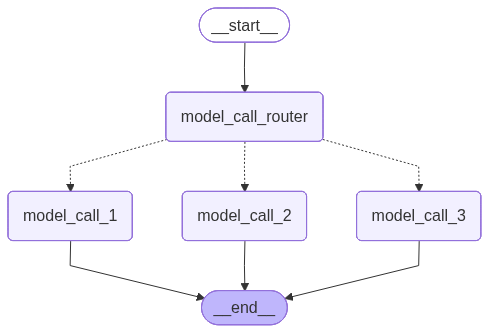

---


## 13.2.4. `Orchestrator-worker`：编排器—工作节点

### 13.2.4.1. 核心思想

编排器先分析任务，动态生成若干子任务，再创建对应数量的 Worker：


```text
                         ┌→ Worker 1 ─┐
输入 → Orchestrator ─────┼→ Worker 2 ─┼→ Synthesizer → 输出
                         ├→ Worker 3 ─┤
                         └→ Worker N ─┘
```


它通常包含三个组件：

| 组件 | 职责 |
|:---|:---|
| **`Orchestrator`**（编排器） | 分析任务、制定计划、生成子任务列表 |
| **`Workers`**（工作节点） | 分别处理各子任务，通常并行执行 |
| **`Synthesizer`**（聚合节点） | 汇总所有 Worker 结果，生成最终答案 |

适合任务数量无法预先确定的场景，例如：

* 根据主题动态生成报告章节
* 修改未知数量的代码文件
* 为多个数据源分别执行分析
* 将长文档动态拆分为若干部分处理

### 13.2.4.2. 和`Parallelization`的区别

| 模式 | 任务数量 |
|:---|:---|
| **`Parallelization`** | 编译图时已确定（静态） |
| **`Orchestrator-worker`** | 运行时动态计算 |

### 13.2.4.3. 本质

**`Orchestrator-worker`** 本质上就是 **`Map-Reduce`**，我们在前面的课程中已经实现过了


```text
Orchestrator：生成 Map 任务
Send：动态分发
Worker：执行 Map
Reducer：合并中间结果
Synthesizer：执行 Reduce
```


### 13.2.4.4. 示例


```python
from typing import Annotated, List, TypedDict
from collections.abc import Sequence

from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain_deepseek import ChatDeepSeek

from operator import add
from dotenv import load_dotenv
from pydantic import BaseModel, Field

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 结构化输出的 Schema
class Section(BaseModel):
    name: str = Field(
        description="报告的章节名称",
    )
    description: str = Field(
        description="本节主题和核心思想的概述",
    )

class Sections(BaseModel):
    sections: List[Section] = Field(
        description="报告的章节列表",
    )

# 编排器
planner = model.with_structured_output(Sections)

# 图状态
class OverAllState(TypedDict):
    topic: str  # 报告主题
    sections: list[Section]  # 报告章节列表
    completed_sections: Annotated[
        list, add
    ]  # 所有工作节点并行写入该字段
    final_report: str  # 最终报告


# 工作节点状态
class WorkerState(TypedDict):
    section: Section
    completed_sections: Annotated[list, add]

# 节点
def orchestrator(state: OverAllState) -> OverAllState:
    """编排器：生成报告编写计划"""

    # 生成报告章节规划
    report_sections = planner.invoke(
        [
            SystemMessage(content="为这份报告生成一个章节规划。"),
            HumanMessage(content=f"报告主题如下：{state['topic']}"),
        ]
    )

    return {"sections": report_sections.sections}

def model_call(state: WorkerState) -> WorkerState:
    """工作节点：编写报告中的一个章节"""

    # 生成章节内容
    section = model.invoke(
        [
            SystemMessage(
                content=(
                    "根据提供的章节名称和章节描述编写报告内容。"
                    "不要在每个章节前添加额外的开场说明。"
                    "使用 Markdown 格式。"
                )
            ),
            HumanMessage(
                content=(
                    f"章节名称：{state['section'].name}\n"
                    f"章节描述：{state['section'].description}"
                )
            ),
        ]
    )

    # 将生成的章节写入已完成章节列表
    return {"completed_sections": [section.content]}


def synthesizer(state: OverAllState) -> OverAllState:
    """将所有章节合成为完整报告"""

    # 获取所有已完成的章节
    completed_sections = state["completed_sections"]

    # 将已完成章节拼接为最终报告
    completed_report_sections = "\n\n---\n\n".join(completed_sections)

    return {"final_report": completed_report_sections}


# 条件边函数：为规划中的每个章节创建一个 model_call 工作节点
def assign_workers(state: OverAllState) -> Sequence[Send]:
    """为规划中的每个章节分配一个工作节点"""

    # 使用 Send API 并行启动各个章节的编写任务
    return [Send("model_call", {"section": s}) for s in state["sections"]]


# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("orchestrator", orchestrator)
builder.add_node("model_call", model_call)
builder.add_node("synthesizer", synthesizer)

# 添加边，连接各个节点
builder.add_edge(START, "orchestrator")
builder.add_conditional_edges(
    "orchestrator",
    assign_workers,
    ["model_call"],
)
builder.add_edge("model_call", "synthesizer")
builder.add_edge("synthesizer", END)

# 编译工作流
graph = builder.compile()

# 调用工作流
state = graph.invoke(
    {"topic": "撰写一份关于大语言模型缩放定律的报告"}
)

from IPython.display import Markdown, display

# 显示工作流图
display(graph)
# 渲染报告
Markdown(state["final_report"])
```


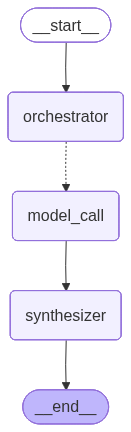


**示例输出（精简）**

```text
引言
缩放定律是深度学习与人工智能领域中的核心理论基础之一。它揭示了模型性能与关键资源（如参数量、数据规模、计算算力）之间普遍存在的幂律关系，即当模型规模、训练数据量或计算预算成比例扩大时，模型的表现能力会呈现出可预测性的提升。这一发现最早源自对语言模型的系统性实证研究，随后在计算机视觉、多模态学习等众多任务中被广泛验证，深刻改变了现代AI研究的范式。
缩放定律的重要性体现在多个层面。从学术研究角度看，它不仅为“更大的模型、更多的数据”提供了科学依据，还催生了以GPT、PaLM、LLaMA为代表的大规模预训练模型浪潮。从工程实践角度看，缩放定律为资源分配提供了量化指导——研究人员可以据此预测模型性能对计算预算的依赖关系，从而制定更高效的训练策略。此外，在探索模型能力涌现性的前沿领域，缩放定律更是理解大语言模型行为边界的关键工具。因此，深入剖析缩放定律的理论内涵、实验验证与局限性，对于把握AI发展的底层逻辑具有不可替代的价值。
本报告将系统梳理缩放定律的研究脉络。后续章节首先阐述语言模型缩放的基本原理与核心公式；随后通过经典实验案例展示缩放定律的实证表现，并讨论其在不同任务与架构中的泛化能力；在此基础上，分析缩放定律的物理极限与开放挑战，包括数据效率、规模收益递减等问题；最后总结缩放定律对AI未来发展的战略启示。全文力求在学术严谨性与可读性之间取得平衡，为读者提供一幅关于缩放定律的全局图景。
缩放定律的基本概念
缩放定律（Scaling Laws）是深度学习中描述模型性能如何随模型规模（参数数量）、数据集规模（训练数据量）以及计算量（训练使用的计算资源，通常以FLOPs表示）变化的经验性规律。这些规律揭示了在大规模训练中，模型性能（例如损失值或下游任务准确率）与上述三个因素之间存在较为平滑且可预测的幂律关系。
具体而言，缩放定律通常由以下关系组成：
模型规模（Model Size）：在给定的数据集和计算预算下，增加模型参数数量（例如从几亿到数千亿）能够显著提升性能，但收益呈现递减趋势。性能提升与模型参数量的幂次方成正比，即 ( L \propto N^{-\alpha} )，其中 ( L ) 为损失， ( N ) 为参数数量， ( \alpha ) 为缩放指数。
数据集规模（Dataset Size）：在固定模型结构和计算资源的情况下，增加训练数据量同样可以降低损失。类似地，损失与数据量的关系可表示为 ( L \propto D^{-\beta} )，其中 ( D ) 为数据集规模， ( \beta ) 为对应的缩放指数。这意味着数据量越大，模型过拟合的风险越小，性能提升越稳定。
计算量（Compute）：将模型规模和数据规模同时考虑，总训练计算量（以FLOPs衡量）与性能的关系可概括为 ( L \propto C^{-\gamma} )，其中 ( C ) 为计算量。研究表明，在最优资源配置下，增加计算量能可靠地提升性能，且存在一个近似固定的计算最优前沿。
这些关系表明，模型性能并非由单一因素决定，而是三者共同作用的结果。缩放定律的核心在于，当预算（计算成本）固定时，存在一组最优的模型规模与数据规模分配，使得性能最大化。例如，若计算预算充足，则应同时扩大模型参数和训练数据；若某一资源受限，则需根据缩放指数的相对大小调整比例。
缩放定律的一个关键结论是：大模型是样本高效的——即随着模型规模增大，同样的数据量能带来更大的性能提升；反过来，大模型也是计算高效的——即同样的计算预算，训练更大的模型（配合适量数据）往往比训练小模型更优。这些规律为现代大规模语言模型的设计，如GPT系列、LLaMA等，提供了理论基础：它们正是遵循“同时扩大模型、数据和计算量”的指导原则。
...（中间日志/重复事件省略）...
面对缩放定律的局限性，研究者正转向非简单缩放的架构创新，以绕过参数扩张的性能瓶颈。例如，混合专家模型（MoE）通过稀疏激活机制，在增加总参数量的同时保持计算成本接近线性增长；维度扩展策略（如线性注意力、长序列建模）尝试替代传统transformer中的二次复杂度注意力机制；此外，结构化权重矩阵（如低秩分解、张量分解）能在不显著增加模型尺寸的前提下提升表达能力。这些创新揭示了更高效的缩放方向：而非盲目提升参数量，优化模型内部的信息流动效率、参数复用率以及计算资源分布。未来，结合神经架构搜索（NAS …（该行元数据省略）
结论与展望
本文围绕缩放定律（Scaling Laws）展开了系统性分析，揭示了大规模模型性能与计算资源、数据规模及参数数量之间存在的幂律关系。核心结论包括：模型性能在相当广泛的范围内随计算预算、数据集大小和参数数量的增加而稳定提升，这一规律为现代深度学习模型的规模化设计提供了理论依据与工程指导。然而，缩放并非无代价，边际收益递减、训练成本激增以及数据质量瓶颈成为进一步扩展的主要制约因素。
在未来研究方向上，稀疏模型（Sparse Models）展现出突破现有缩放瓶颈的潜力。通过引入混合专家系统（MoE）、参数高效微调及动态结构剪枝等机制，稀疏模型可在不显著增加计算开销的前提下，实现参数规模的有效放大。该方向有望打破密集模型中的线性缩放约束，推动模型容量与效率的协同增长。
多模态缩放（Multimodal Scaling）是另一个值得关注的前沿领域。当前缩放定律多聚焦于单一模态（如文本或图像），而跨模态联合训练下性能与资源间的映射关系尚不明确。未来亟需建立针对多模态输入的统一缩放框架，探索视觉、语言、音频等异构数据在共同训练过程中的交互效应与计算效率优化策略。
此外，训练数据质量与来源的多样性、模型泛化边界、以及缩放定律在非自监督学习范式（如强化学习、在线学习）中的适用性，构成后续研究需要深入探讨的关键议题。随着实际部署对能耗、推理速度和环境可持续性提出更高要求，缩放定律的应用亦需与资源约束感知模型设计及低碳训练方法相结合。总之，未来研究需在理解缩放基本规律的基础上，拓展其边界，提升其可控性，并为其在更广泛人工智能系统中的部署提供理论支持与实践路径。
```


---


## 13.2.5. `Evaluator-optimizer`：评估器—优化器

### 13.2.5.1. 核心思想

一个节点生成结果，另一个节点评估结果；不合格就携带反馈重新生成：


```text
          ┌──────────────────────┐
          ↓                      │
输入 → Generator → Evaluator ────┤
                      ├─ 不合格 ─┘
                      └─ 合格 → END
```


适合：

* 翻译质量迭代
* 代码生成与代码审查
* 文案生成与合规检查
* **`SQL`** 生成与语法验证
* 报告生成与事实检查
* 人工审批后修改

这种模式适用于存在明确质量标准，但通常需要多轮修改才能满足标准的任务。评估者既可以是 **`LLM`**，也可以是规则、测试程序或人类。

### 13.2.5.2. 必要的控制

为了避免无限循环，必须引入递归限制，可以是

- 优雅退出的主动方法
- 异常中断的被动方法

第 02 篇给出了两种退出办法：节点主动检查剩余步数返回 END，或在图外捕获 GraphRecursionError。生产流程还应设置最大迭代次数和明确质量阈值。

### 13.2.5.3. 示例


```python
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
from pydantic import BaseModel, Field

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

# 图状态
class OverAllState(TypedDict):
    joke: str
    topic: str
    feedback: str
    funny_or_not: str

# 定义用于结构化输出的 Schema，作为笑话评估依据
class Feedback(BaseModel):
    grade: Literal["好笑", "不好笑"] = Field(
        description="判断这个笑话是否好笑。",
    )
    feedback: str = Field(
        description="如果笑话不好笑，请给出具体的改进建议。",
    )

# 为大模型添加结构化输出能力，定义评估器
evaluator = model.with_structured_output(Feedback)

# 节点
def model_call_generator(state: OverAllState) -> OverAllState:
    """大模型生成笑话"""

    if state.get("feedback"):
        msg = model.invoke(
            f"""
            写一个关于“{state['topic']}”的笑话。

            请参考下面的改进建议：
            {state['feedback']}
            """
        )
    else:
        msg = model.invoke(f"写一个关于“{state['topic']}”的笑话")

    return {"joke": msg.content}


def model_call_evaluator(state: OverAllState) -> OverAllState:
    """大模型评估笑话"""

    grade = evaluator.invoke(
        f"""
        请评估下面这个笑话是否好笑：

        {state['joke']}
        """
    )

    return {
        "funny_or_not": grade.grade,
        "feedback": grade.feedback,
    }


# 条件边函数：根据评估结果决定结束流程，或者返回笑话生成节点
def route_joke(state: OverAllState) -> Literal["accept", "reject_and_feedback", END]:
    """根据评估结果决定接受笑话或根据反馈重新生成"""

    if state["funny_or_not"] == "好笑":
        return "accept"
    elif state["funny_or_not"] == "不好笑":
        return "reject_and_feedback"
    return END

# 构建工作流
builder = StateGraph(state_schema=OverAllState)

# 添加节点
builder.add_node("model_call_generator", model_call_generator)
builder.add_node("model_call_evaluator", model_call_evaluator)

# 添加边，连接各个节点
builder.add_edge(START, "model_call_generator")
builder.add_edge("model_call_generator", "model_call_evaluator")
builder.add_conditional_edges(
    "model_call_evaluator",
    route_joke,
    {
        # route_joke 返回的名称：接下来要执行的节点
        "accept": END,
        "reject_and_feedback": "model_call_generator",
    },
)

# 编译工作流
graph = builder.compile()

# 调用工作流
state = graph.invoke({"topic": "猫"})
print(state["joke"])

# 显示工作流图
from IPython.display import display
display(graph)
```


```text
# 关于猫的笑话

一只猫去应聘当保安。

面试官问：“你有什么特长？”

猫说：“我精通‘猫步’，走路悄无声息，可以抓到任何小偷。”

面试官点头：“不错。那面对危险情况，你会怎么处理？”

猫淡定地说：“我会用‘九条命’精神，即使失败一次，还有八次机会总结经验。”

面试官很满意：“那我们决定录用你。不过，我们有个夜班岗位，你介意夜间工作吗？”

猫“喵”了一声：“正合我意，白天我要晒着太阳睡觉的。”

然后面试官又问：“最后一个问题——你如果发现仓库里有老鼠，会怎么处置？”

猫瞪大了眼睛：“老鼠？那是我请来的线人！没有老鼠，我怎么假装抓到战绩，让你们给我加罐头？”

面试官：“……你被开除了。”

猫耸耸肩：“无所谓，反正我还有八条命去找下一份工作。”
```


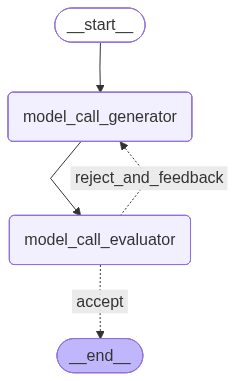

---


## 13.2.6. `Agent`：智能体循环

### 13.2.6.1. 核心思想

前面的运行图设计模式都属于 **`Workflow`**，**`Agent`** 与 **`Workflow`** 最大的不同是：

> 开发者不再预先确定每一步具体执行什么，而是让 **`LLM`** 根据当前消息和工具结果决定下一步行为。

基本拓扑是：


```text
          ┌─────────────────┐
          ↓                 │
输入 → LLM 决策 → 是否调用工具
                ├─ 是 → Tool ┘
                └─ 否 → END
```


这是一种工具调用 Agent 循环：模型先判断是否需要工具，工具结果回到消息列表，然后再次交给模型。常用于实现 ReAct（推理与行动交替）的工作方式。

**`Agent`** 适合问题求解步骤和工具调用顺序无法预先确定的场景。开发者仍然负责提供工具集合、系统提示词、权限和边界，但具体执行过程由模型动态决定。

### 13.2.6.2. 示例


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt.tool_node import ToolNode

from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from langchain.tools import tool

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    根据城市查询当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气不错"

tools = [get_weather]
model_with_tools = model.bind_tools(tools=tools)

def model_node(state: MessagesState) -> MessagesState:
    messages = state["messages"]
    response = model_with_tools.invoke(input=messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    last_msg = state["messages"][-1]

    if last_msg.tool_calls:
        return "tool_node"
    return END

builder = StateGraph(state_schema=MessagesState)
builder.add_node("model_node", model_node)
builder.add_node("tool_node", ToolNode(tools=tools))

builder.add_edge(START, "model_node")
builder.add_conditional_edges("model_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "model_node")

graph = builder.compile()

response = graph.invoke({"messages": [HumanMessage(content="今天北京天气怎么样？")]})
for msg in response["messages"]:
    msg.pretty_print()

from IPython.display import display
display(graph)
```


```text
================================ Human Message =================================

今天北京天气怎么样？
================================== Ai Message ==================================

好的，我来帮你查询一下今天北京的天气情况。
Tool Calls:
  get_weather (call_00_3kFtzQHjGl7VJkfBi5280445)
 Call ID: call_00_3kFtzQHjGl7VJkfBi5280445
  Args:
    city: 北京
================================= Tool Message =================================
Name: get_weather

北京 今天天气不错
================================== Ai Message ==================================

今天北京的**天气不错**哦！☀️

看起来是个适合出门活动的好天气，不用太担心下雨或恶劣天气的问题。如果你有具体的户外活动计划，应该会比较顺利。

请问还有其他需要帮忙的吗？😊
```


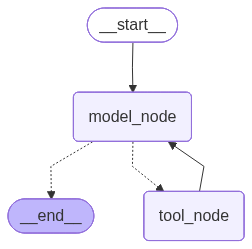


## 选型与复习

| 需求 | 优先选择 | 实现时的关键判断 |
| --- | --- | --- |
| 展示最终逐步生成的回答 | `messages` | 从消息片段取内容，可按节点元数据过滤来源 |
| 展示“检索完成、开始写作”等进度 | `custom` | 通过 writer 显式写出业务进度 |
| 更新界面的节点结果 | `updates` | 消费节点更新，不必传输每轮完整状态 |
| 调试执行过程 | `tasks` / `checkpoints` / `debug` | 观察任务和状态；检查点模式需配置 checkpointer |
| 固定节点之间复用状态 | 子图直接作为父图节点 | 共享字段的名称和合并规则须对齐 |
| 父子图使用不同的数据结构 | 在包装节点里调用子图 | 显式映射输入和输出 |
| 子任务每次独立执行 | 默认 Per-invocation | 可恢复执行，但不自动继承上一调用的子图会话 |
| 子 Agent 需要多轮记忆 | Per-thread | 同一线程的状态连续；为不同子 Agent 使用独立父图节点 |
| 固定数量的独立任务 | Parallelization | 等待所有分支汇聚，处理并发写同一字段的 Reducer |
| 运行时才知道任务数量 | Orchestrator-worker | 用 Send 分发任务，再汇总 Worker 结果 |
| 质量标准明确，需要迭代修订 | Evaluator-optimizer | 设置最大迭代次数或递归限制，并保留评估反馈 |
| 下一步动作由模型决定 | Agent 循环 | 工具结果回写消息；无工具调用时结束；设置循环边界 |

**面试提示**：Workflow 通常由开发者规定步骤和可走的路径，Agent 则让模型在给定工具和边界内选择下一步。LangGraph 可以把两者组合在同一张图里。子图的“保存检查点”和“跨调用保留记忆”是不同维度；默认 Per-invocation 能支持中断恢复，Per-thread 才用于连续会话。
